In [11]:
import pandas as pd
import numpy as np

file_path = r"C:\Users\vicky\OneDrive\Desktop\PROJECTS\Healthcare_Cost_Optimization_Analytics\data\Analytical_Dataset\healthcare_analytical_dataset.csv"

master = pd.read_csv(file_path)

print("Dataset Shape:", master.shape)

Dataset Shape: (61459, 58)


In [12]:
# Identify the top 1% highest-cost encounters

high_cost_cutoff = master["TOTAL_CLAIM_COST"].quantile(0.99)

master["HIGH_COST_FLAG"] = (
    master["TOTAL_CLAIM_COST"] >= high_cost_cutoff
)

print("99th Percentile Cost Cutoff:", round(high_cost_cutoff, 2))
print("High-Cost Encounters:", master["HIGH_COST_FLAG"].sum())
print("Other Encounters:", (~master["HIGH_COST_FLAG"]).sum())

99th Percentile Cost Cutoff: 45209.38
High-Cost Encounters: 615
Other Encounters: 60844


In [13]:
high_cost_summary = (
    master.groupby("HIGH_COST_FLAG")["TOTAL_CLAIM_COST"]
    .agg(
        Encounter_Count="count",
        Total_Cost="sum",
        Average_Cost="mean",
        Median_Cost="median"
    )
    .reset_index()
)

high_cost_summary

,HIGH_COST_FLAG,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
0,False,60844,2.115127e+08,3476.310924,786.33
1,True,615,4.352117e+07,70766.123902,65833.14


In [14]:
factor_columns = [
    "ENCOUNTERCLASS",
    "PATIENT_GENDER",
    "RACE",
    "ETHNICITY",
    "MARITAL",
    "AGE_AT_ENCOUNTER",
    "condition_count",
    "procedure_count",
    "medication_count",
    "observation_count",
    "careplan_count",
    "imaging_study_count",
    "PAYER_NAME"
]

for col in factor_columns:
    print("\n" + "=" * 70)
    print("FACTOR:", col)
    
    if master[col].dtype == "object":
        result = (
            master.groupby(["HIGH_COST_FLAG", col])["TOTAL_CLAIM_COST"]
            .agg(["count", "mean"])
            .reset_index()
        )
    else:
        result = (
            master.groupby("HIGH_COST_FLAG")[col]
            .agg(["mean", "median"])
            .reset_index()
        )
    
    print(result)


FACTOR: ENCOUNTERCLASS


TypeError: dtype 'str' does not support operation 'mean'

In [15]:
# Analyze characteristics of high-cost vs other encounters

categorical_factors = [
    "ENCOUNTERCLASS",
    "PATIENT_GENDER",
    "RACE",
    "ETHNICITY",
    "MARITAL",
    "PAYER_NAME"
]

numerical_factors = [
    "AGE_AT_ENCOUNTER",
    "condition_count",
    "procedure_count",
    "medication_count",
    "observation_count",
    "careplan_count",
    "imaging_study_count"
]

# -------------------------------
# CATEGORICAL FACTORS
# -------------------------------

for col in categorical_factors:
    print("\n" + "=" * 70)
    print("FACTOR:", col)
    
    result = (
        master.groupby(["HIGH_COST_FLAG", col], dropna=False)
        .agg(
            Encounter_Count=("TOTAL_CLAIM_COST", "size"),
            Average_Cost=("TOTAL_CLAIM_COST", "mean")
        )
        .reset_index()
    )
    
    print(result.to_string(index=False))


# -------------------------------
# NUMERICAL FACTORS
# -------------------------------

print("\n" + "=" * 70)
print("NUMERICAL FACTORS")
print("=" * 70)

numeric_result = (
    master.groupby("HIGH_COST_FLAG")[numerical_factors]
    .agg(["mean", "median"])
)

print(numeric_result)


FACTOR: ENCOUNTERCLASS
 HIGH_COST_FLAG ENCOUNTERCLASS  Encounter_Count  Average_Cost
          False     ambulatory            19670   5125.986513
          False      emergency             2122   4914.400405
          False      inpatient             1719   8167.419959
          False     outpatient            10794   2648.696217
          False     urgentcare             2538   5363.493073
          False       wellness            24001   1833.831182
           True     ambulatory              454  67102.874229
           True      emergency               46 146871.666739
           True      inpatient                9 123094.676667
           True     outpatient               43  47714.068140
           True     urgentcare               26  48239.660000
           True       wellness               37  50988.552703

FACTOR: PATIENT_GENDER
 HIGH_COST_FLAG PATIENT_GENDER  Encounter_Count  Average_Cost
          False              F            35054   3489.801449
          False       

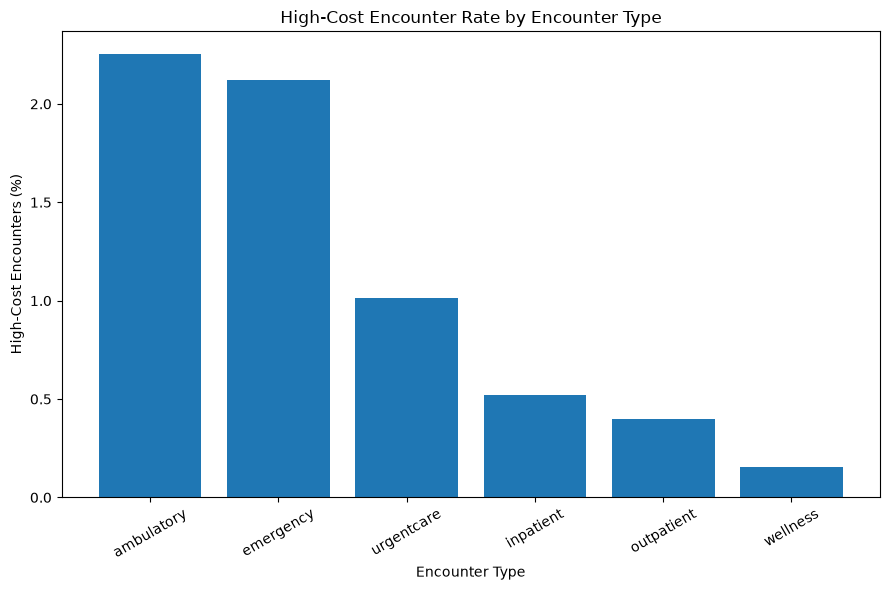

In [16]:
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Visualization 1: High-Cost Encounter Rate by Encounter Type
# ---------------------------------------------------------

encounter_cost_rate = (
    master.groupby("ENCOUNTERCLASS")
    .agg(
        Total_Encounters=("HIGH_COST_FLAG", "size"),
        High_Cost_Encounters=("HIGH_COST_FLAG", "sum")
    )
    .reset_index()
)

encounter_cost_rate["High_Cost_Rate"] = (
    encounter_cost_rate["High_Cost_Encounters"]
    / encounter_cost_rate["Total_Encounters"]
    * 100
)

encounter_cost_rate = encounter_cost_rate.sort_values(
    "High_Cost_Rate",
    ascending=False
)

plt.figure(figsize=(9, 6))

plt.bar(
    encounter_cost_rate["ENCOUNTERCLASS"],
    encounter_cost_rate["High_Cost_Rate"]
)

plt.title("High-Cost Encounter Rate by Encounter Type")
plt.xlabel("Encounter Type")
plt.ylabel("High-Cost Encounters (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

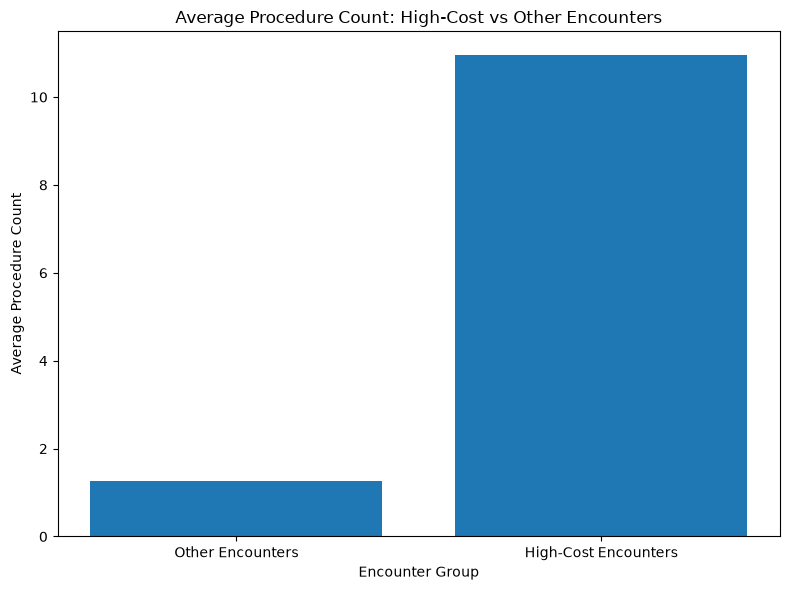

In [17]:
# ---------------------------------------------------------
# Visualization 2: Procedure Utilization
# ---------------------------------------------------------

procedure_comparison = (
    master.groupby("HIGH_COST_FLAG")["procedure_count"]
    .mean()
    .reset_index()
)

procedure_comparison["Group"] = procedure_comparison["HIGH_COST_FLAG"].map({
    False: "Other Encounters",
    True: "High-Cost Encounters"
})

procedure_comparison = procedure_comparison.sort_values("HIGH_COST_FLAG")

plt.figure(figsize=(8, 6))

plt.bar(
    procedure_comparison["Group"],
    procedure_comparison["procedure_count"]
)

plt.title("Average Procedure Count: High-Cost vs Other Encounters")
plt.xlabel("Encounter Group")
plt.ylabel("Average Procedure Count")
plt.tight_layout()
plt.show()

In [18]:
# ---------------------------------------------------------
# Cost Optimization Q2
# 30-Day Repeat Encounter Analysis
# ---------------------------------------------------------

# Sort encounters by patient and start time
master = master.sort_values(["PATIENT", "START"]).copy()

# Convert START to datetime
master["START"] = pd.to_datetime(master["START"])

# Calculate days until the patient's next encounter
master["NEXT_ENCOUNTER_DATE"] = (
    master.groupby("PATIENT")["START"].shift(-1)
)

master["DAYS_TO_NEXT_ENCOUNTER"] = (
    master["NEXT_ENCOUNTER_DATE"] - master["START"]
).dt.total_seconds() / (60 * 60 * 24)

# Flag encounters followed by another encounter within 30 days
master["REPEAT_30D_FLAG"] = (
    master["DAYS_TO_NEXT_ENCOUNTER"].between(0, 30, inclusive="both")
)

print("Repeat encounters within 30 days:",
      master["REPEAT_30D_FLAG"].sum())

print("Non-repeat encounters:",
      (~master["REPEAT_30D_FLAG"]).sum())

Repeat encounters within 30 days: 23594
Non-repeat encounters: 37865


In [19]:
repeat_by_type = (
    master.groupby("ENCOUNTERCLASS")
    .agg(
        Total_Encounters=("Id", "size"),
        Repeat_Encounters=("REPEAT_30D_FLAG", "sum"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum")
    )
    .reset_index()
)

repeat_by_type["Repeat_Rate"] = (
    repeat_by_type["Repeat_Encounters"]
    / repeat_by_type["Total_Encounters"]
    * 100
)

repeat_by_type["Repeat_Cost"] = (
    master[master["REPEAT_30D_FLAG"]]
    .groupby("ENCOUNTERCLASS")["TOTAL_CLAIM_COST"]
    .sum()
    .reindex(repeat_by_type["ENCOUNTERCLASS"])
    .fillna(0)
    .values
)

repeat_by_type["Repeat_Average_Cost"] = (
    master[master["REPEAT_30D_FLAG"]]
    .groupby("ENCOUNTERCLASS")["TOTAL_CLAIM_COST"]
    .mean()
    .reindex(repeat_by_type["ENCOUNTERCLASS"])
    .fillna(0)
    .values
)

repeat_by_type = repeat_by_type.sort_values(
    "Repeat_Cost",
    ascending=False
)

repeat_by_type

,ENCOUNTERCLASS,Total_Encounters,Repeat_Encounters,Total_Cost,Repeat_Rate,Repeat_Cost,Repeat_Average_Cost
0,ambulatory,20124,12233,1.312929e+08,60.788114,1.011060e+08,8265.023479
4,urgentcare,2564,2234,1.486678e+07,87.129485,1.413654e+07,6327.906477
3,outpatient,10837,4675,3.064173e+07,43.139245,1.367380e+07,2924.876445
5,wellness,24038,2617,4.590036e+07,10.886929,6.289111e+06,2403.175862
2,inpatient,1728,825,1.514765e+07,47.743056,6.120118e+06,7418.324461
1,emergency,2168,1010,1.718445e+07,46.586716,6.109803e+06,6049.310307


In [20]:
high_cost_repeat = master[
    (master["REPEAT_30D_FLAG"]) &
    (master["HIGH_COST_FLAG"])
]

print("High-cost repeat encounters:", len(high_cost_repeat))

print(
    "Total cost of high-cost repeat encounters: $",
    round(high_cost_repeat["TOTAL_CLAIM_COST"].sum(), 2)
)

print(
    "Average cost of high-cost repeat encounters: $",
    round(high_cost_repeat["TOTAL_CLAIM_COST"].mean(), 2)
)

High-cost repeat encounters: 418
Total cost of high-cost repeat encounters: $ 27614312.63
Average cost of high-cost repeat encounters: $ 66062.95


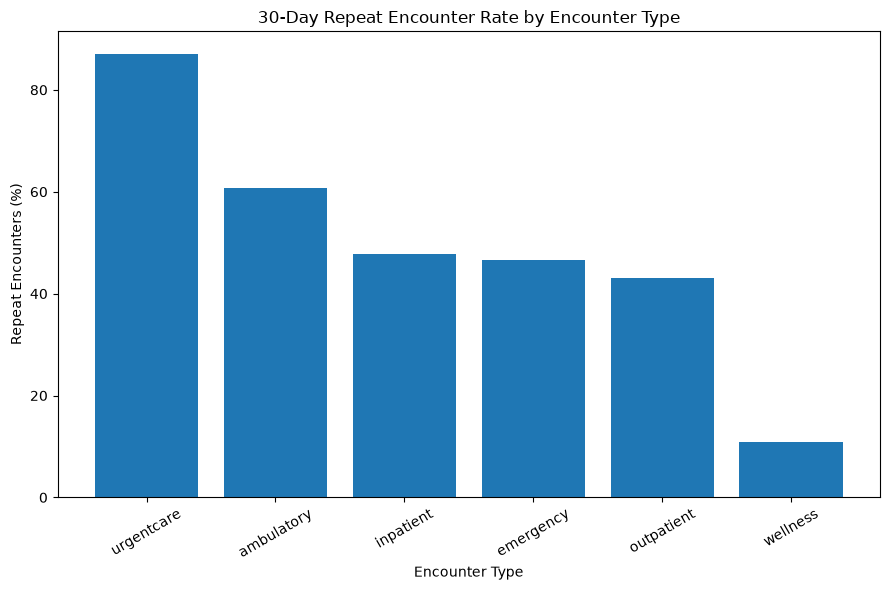

In [21]:
# ---------------------------------------------------------
# Q2 Visualization 1
# Repeat Encounter Rate by Encounter Type
# ---------------------------------------------------------

plot_data = repeat_by_type.sort_values(
    "Repeat_Rate",
    ascending=False
)

plt.figure(figsize=(9, 6))

plt.bar(
    plot_data["ENCOUNTERCLASS"],
    plot_data["Repeat_Rate"]
)

plt.title("30-Day Repeat Encounter Rate by Encounter Type")
plt.xlabel("Encounter Type")
plt.ylabel("Repeat Encounters (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

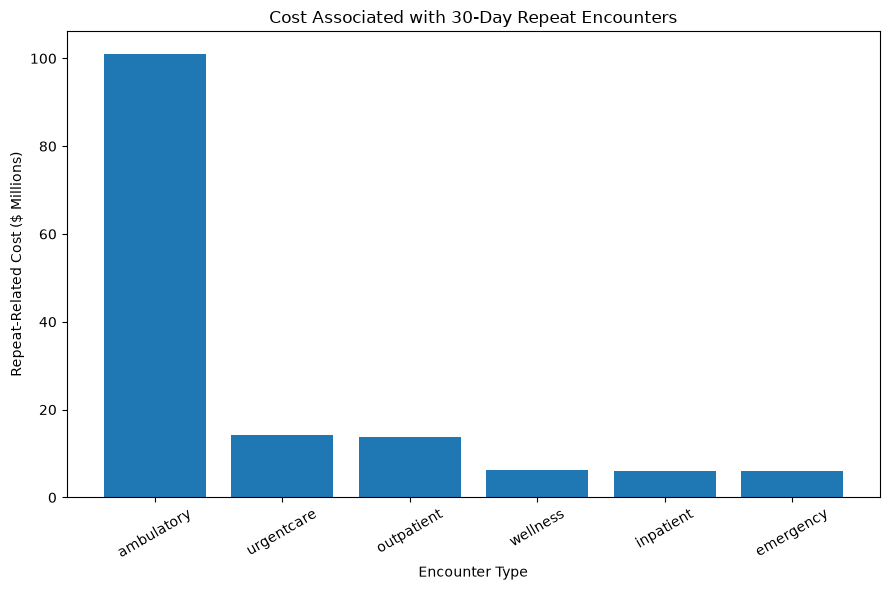

In [22]:
# ---------------------------------------------------------
# Q2 Visualization 2
# Total Cost Associated with Repeat Encounters
# ---------------------------------------------------------

plot_data = repeat_by_type.sort_values(
    "Repeat_Cost",
    ascending=False
)

plt.figure(figsize=(9, 6))

plt.bar(
    plot_data["ENCOUNTERCLASS"],
    plot_data["Repeat_Cost"] / 1_000_000
)

plt.title("Cost Associated with 30-Day Repeat Encounters")
plt.xlabel("Encounter Type")
plt.ylabel("Repeat-Related Cost ($ Millions)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [23]:
# ---------------------------------------------------------
# Q2 Validation — Check 30-Day Repeat Encounter Definition
# ---------------------------------------------------------

# Check the first and last few rows after sorting
validation = master[
    [
        "PATIENT",
        "START",
        "NEXT_ENCOUNTER_DATE",
        "DAYS_TO_NEXT_ENCOUNTER",
        "REPEAT_30D_FLAG"
    ]
].copy()

print("Total encounters:", len(validation))

print("\nRepeat flag counts:")
print(validation["REPEAT_30D_FLAG"].value_counts(dropna=False))

print("\nRepeat rate:")
print(
    validation["REPEAT_30D_FLAG"].mean() * 100,
    "%"
)

print("\nDays-to-next-encounter summary:")
print(
    validation["DAYS_TO_NEXT_ENCOUNTER"].describe()
)

Total encounters: 61459

Repeat flag counts:
REPEAT_30D_FLAG
False    37865
True     23594
Name: count, dtype: int64

Repeat rate:
38.38982085618055 %

Days-to-next-encounter summary:
count    60296.000000
mean       224.453423
std        459.164529
min          0.000000
25%         19.742089
50%         70.000000
75%        371.000000
max      17241.375000
Name: DAYS_TO_NEXT_ENCOUNTER, dtype: float64


In [24]:
# Check exactly how many encounters have a next encounter
# within different day thresholds

for days in [0, 1, 7, 14, 30, 31]:
    count = (
        master["DAYS_TO_NEXT_ENCOUNTER"]
        .between(0, days, inclusive="both")
        .sum()
    )
    
    print(f"Within {days:>2} days: {count}")

Within  0 days: 855
Within  1 days: 2378
Within  7 days: 10379
Within 14 days: 13782
Within 30 days: 23594
Within 31 days: 23782


In [25]:
# Check whether same-day encounters are included

same_day = (
    master["DAYS_TO_NEXT_ENCOUNTER"] == 0
).sum()

print("Same-day next encounters:", same_day)

print(
    "Repeat encounters including same-day:",
    master["DAYS_TO_NEXT_ENCOUNTER"]
    .between(0, 30, inclusive="both")
    .sum()
)

print(
    "Repeat encounters excluding same-day:",
    master["DAYS_TO_NEXT_ENCOUNTER"]
    .between(0, 30, inclusive="neither")
    .sum()
)

Same-day next encounters: 855
Repeat encounters including same-day: 23594
Repeat encounters excluding same-day: 21931


In [26]:
# Final 30-day repeat definition used in EDA
master["REPEAT_30D_FLAG"] = (
    (master["DAYS_TO_NEXT_ENCOUNTER"] > 0) &
    (master["DAYS_TO_NEXT_ENCOUNTER"] <= 30)
)

print("Final 30-day repeat encounters:",
      master["REPEAT_30D_FLAG"].sum())

print(
    "Final repeat rate:",
    round(master["REPEAT_30D_FLAG"].mean() * 100, 2),
    "%"
)

Final 30-day repeat encounters: 22739
Final repeat rate: 37.0 %


In [27]:
# Q2 — Corrected 30-Day Repeat Encounter Analysis

# Repeat encounters by encounter type
repeat_by_type = (
    master.groupby("ENCOUNTERCLASS")
    .agg(
        total_encounters=("Id", "count"),
        repeat_encounters=("REPEAT_30D_FLAG", "sum"),
        repeat_rate=("REPEAT_30D_FLAG", "mean"),
        repeat_total_cost=("TOTAL_CLAIM_COST",
                           lambda x: x[master.loc[x.index, "REPEAT_30D_FLAG"]].sum()),
        repeat_avg_cost=("TOTAL_CLAIM_COST",
                         lambda x: x[master.loc[x.index, "REPEAT_30D_FLAG"]].mean())
    )
    .reset_index()
)

repeat_by_type["repeat_rate"] = repeat_by_type["repeat_rate"] * 100

repeat_by_type = repeat_by_type.sort_values(
    "repeat_total_cost",
    ascending=False
)

print("Repeat Encounters by Encounter Type:")
display(repeat_by_type)


# Overall repeat vs non-repeat cost
repeat_summary = (
    master.groupby("REPEAT_30D_FLAG")["TOTAL_CLAIM_COST"]
    .agg(["count", "sum", "mean", "median"])
    .reset_index()
)

repeat_summary["REPEAT_30D_FLAG"] = repeat_summary["REPEAT_30D_FLAG"].map(
    {True: "Repeat", False: "Non-Repeat"}
)

print("\nOverall Repeat vs Non-Repeat Cost:")
display(repeat_summary)


# High-cost + repeat overlap
high_cost_repeat = master[
    (master["HIGH_COST_FLAG"] == True) &
    (master["REPEAT_30D_FLAG"] == True)
]

print("\nHigh-Cost Repeat Encounters:")
print("Count:", len(high_cost_repeat))
print("Total Cost: $", round(high_cost_repeat["TOTAL_CLAIM_COST"].sum(), 2))
print("Average Cost: $", round(high_cost_repeat["TOTAL_CLAIM_COST"].mean(), 2))

Repeat Encounters by Encounter Type:


,ENCOUNTERCLASS,total_encounters,repeat_encounters,repeat_rate,repeat_total_cost,repeat_avg_cost
0,ambulatory,20124,11945,59.356987,98888323.61,8278.637389
4,urgentcare,2564,2214,86.349454,14044682.81,6343.578505
3,outpatient,10837,4628,42.705546,13545294.40,2926.813829
2,inpatient,1728,825,47.743056,6120117.68,7418.324461
5,wellness,24038,2264,9.418421,5845802.27,2582.068140
1,emergency,2168,863,39.806273,5234198.42,6065.119838



Overall Repeat vs Non-Repeat Cost:


,REPEAT_30D_FLAG,count,sum,mean,median
0,Non-Repeat,38720,1.113554e+08,2875.914486,786.33
1,Repeat,22739,1.436784e+08,6318.590052,645.81



High-Cost Repeat Encounters:
Count: 391
Total Cost: $ 25756418.13
Average Cost: $ 65873.19


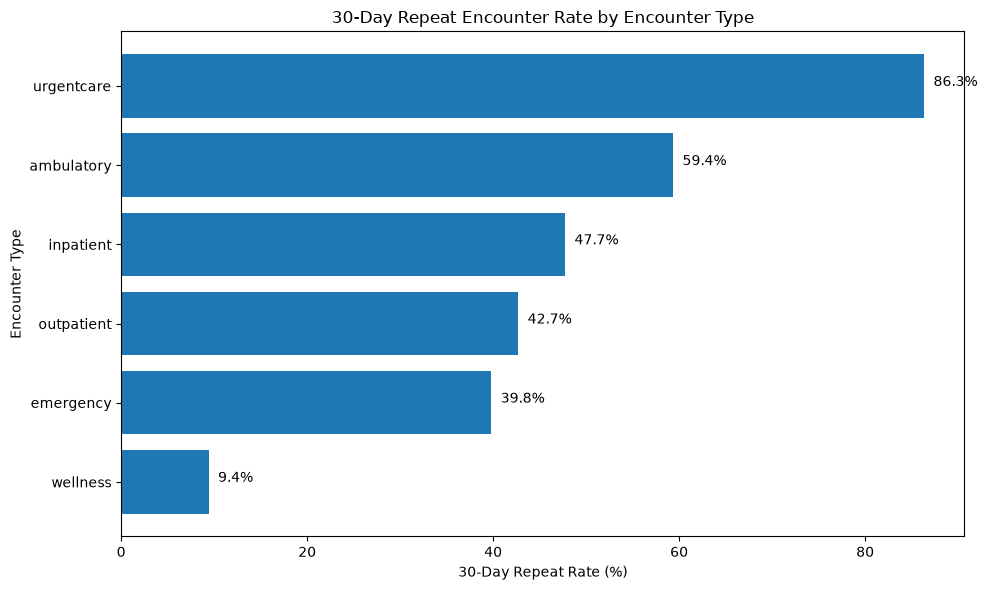

In [28]:
# Q2 Visualization 1
# 30-Day Repeat Encounter Rate by Encounter Type

import matplotlib.pyplot as plt

plot_data = repeat_by_type.sort_values(
    "repeat_rate",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["ENCOUNTERCLASS"],
    plot_data["repeat_rate"]
)

plt.xlabel("30-Day Repeat Rate (%)")
plt.ylabel("Encounter Type")
plt.title("30-Day Repeat Encounter Rate by Encounter Type")

for i, value in enumerate(plot_data["repeat_rate"]):
    plt.text(
        value + 1,
        i,
        f"{value:.1f}%"
    )

plt.tight_layout()
plt.show()

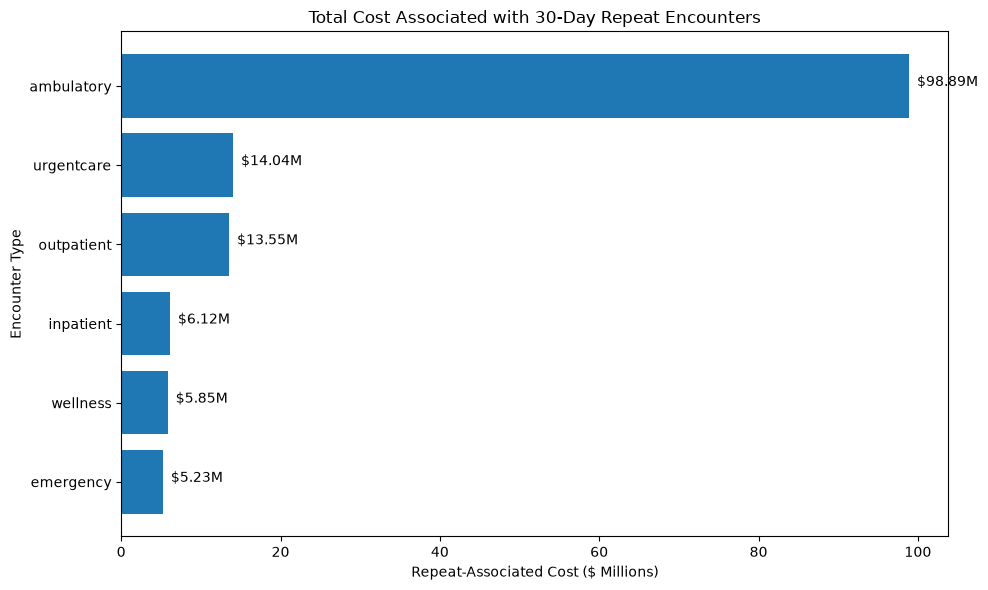

In [29]:
# Q2 Visualization 2
# Total Cost Associated with 30-Day Repeat Encounters

import matplotlib.pyplot as plt

plot_data = repeat_by_type.sort_values(
    "repeat_total_cost",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["ENCOUNTERCLASS"],
    plot_data["repeat_total_cost"] / 1_000_000
)

plt.xlabel("Repeat-Associated Cost ($ Millions)")
plt.ylabel("Encounter Type")
plt.title("Total Cost Associated with 30-Day Repeat Encounters")

for i, value in enumerate(plot_data["repeat_total_cost"] / 1_000_000):
    plt.text(
        value + 1,
        i,
        f"${value:.2f}M"
    )

plt.tight_layout()
plt.show()

In [30]:
# Cost Optimization Q3
# Clinical Utilization vs Healthcare Cost

utilization_features = [
    "procedure_count",
    "medication_count",
    "observation_count",
    "condition_count",
    "careplan_count",
    "imaging_study_count",
    "device_count",
    "supply_count"
]

utilization_summary = []

for feature in utilization_features:
    
    temp = (
        master.groupby(feature)["TOTAL_CLAIM_COST"]
        .agg(
            encounter_count="count",
            average_cost="mean",
            median_cost="median",
            total_cost="sum"
        )
        .reset_index()
    )
    
    temp["utilization_feature"] = feature
    
    utilization_summary.append(temp)

utilization_summary = pd.concat(
    utilization_summary,
    ignore_index=True
)

print("Clinical Utilization vs Healthcare Cost Analysis:")
display(utilization_summary)

Clinical Utilization vs Healthcare Cost Analysis:


,procedure_count,encounter_count,average_cost,median_cost,total_cost,utilization_feature,medication_count,observation_count,condition_count,careplan_count,imaging_study_count,device_count,supply_count
0,0.0,35605,1774.833619,269.680,63192951.00,procedure_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.0,10746,7457.679775,3178.360,80140226.86,procedure_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.0,3254,8098.412674,8477.305,26352234.84,procedure_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3.0,2355,9869.198781,9947.300,23241963.13,procedure_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.0,1838,4232.375631,1021.725,7779106.41,procedure_count,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,NaN,4,21541.085000,21948.635,86164.34,supply_count,NaN,NaN,NaN,NaN,NaN,NaN,60.0
164,NaN,3,20379.530000,20542.200,61138.59,supply_count,NaN,NaN,NaN,NaN,NaN,NaN,66.0
165,NaN,4,21811.445000,21036.290,87245.78,supply_count,NaN,NaN,NaN,NaN,NaN,NaN,72.0
166,NaN,5,18657.914000,23128.210,93289.57,supply_count,NaN,NaN,NaN,NaN,NaN,NaN,78.0


In [31]:
# Q3 — Correlation between Clinical Utilization and Healthcare Cost

utilization_correlations = (
    master[utilization_features + ["TOTAL_CLAIM_COST"]]
    .corr()["TOTAL_CLAIM_COST"]
    .drop("TOTAL_CLAIM_COST")
    .sort_values(ascending=False)
)

print("Correlation with TOTAL_CLAIM_COST:")
display(utilization_correlations.to_frame("correlation"))

Correlation with TOTAL_CLAIM_COST:


,correlation
procedure_count,0.317238
device_count,0.161899
careplan_count,0.112748
imaging_study_count,0.057567
supply_count,0.052537
medication_count,0.048055
observation_count,-0.004210
condition_count,-0.015844


In [32]:
# Q3 — Procedure Intensity vs Healthcare Cost

procedure_analysis = (
    master.groupby("procedure_count")
    .agg(
        encounter_count=("Id", "count"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        median_cost=("TOTAL_CLAIM_COST", "median"),
        total_cost=("TOTAL_CLAIM_COST", "sum")
    )
    .reset_index()
)

print("Procedure Count vs Healthcare Cost:")
display(procedure_analysis)

Procedure Count vs Healthcare Cost:


,procedure_count,encounter_count,average_cost,median_cost,total_cost
0,0,35605,1774.833619,269.680,63192951.00
1,1,10746,7457.679775,3178.360,80140226.86
2,2,3254,8098.412674,8477.305,26352234.84
3,3,2355,9869.198781,9947.300,23241963.13
4,4,1838,4232.375631,1021.725,7779106.41
5,5,2397,4919.251097,926.850,11791444.88
6,6,2320,3111.425556,926.850,7218507.29
7,7,1709,3785.632826,1274.670,6469646.50
8,8,675,6633.228163,1392.350,4477429.01
9,9,183,9047.231038,1523.080,1655643.28


In [33]:
# Q3 — Procedure Intensity Groups

master["procedure_group"] = pd.cut(
    master["procedure_count"],
    bins=[-1, 0, 1, 3, 5, float("inf")],
    labels=["0", "1", "2–3", "4–5", "6+"]
)

procedure_group_summary = (
    master.groupby("procedure_group", observed=False)
    .agg(
        encounter_count=("Id", "count"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        median_cost=("TOTAL_CLAIM_COST", "median"),
        total_cost=("TOTAL_CLAIM_COST", "sum")
    )
    .reset_index()
)

print("Procedure Intensity Group vs Healthcare Cost:")
display(procedure_group_summary)

Procedure Intensity Group vs Healthcare Cost:


,procedure_group,encounter_count,average_cost,median_cost,total_cost
0,0,35605,1774.833619,269.68,63192951.00
1,1,10746,7457.679775,3178.36,80140226.86
2,2–3,5609,8841.896589,9034.31,49594197.97
3,4–5,4235,4621.145523,926.85,19570551.29
4,6+,5264,8080.528298,1248.80,42535900.96


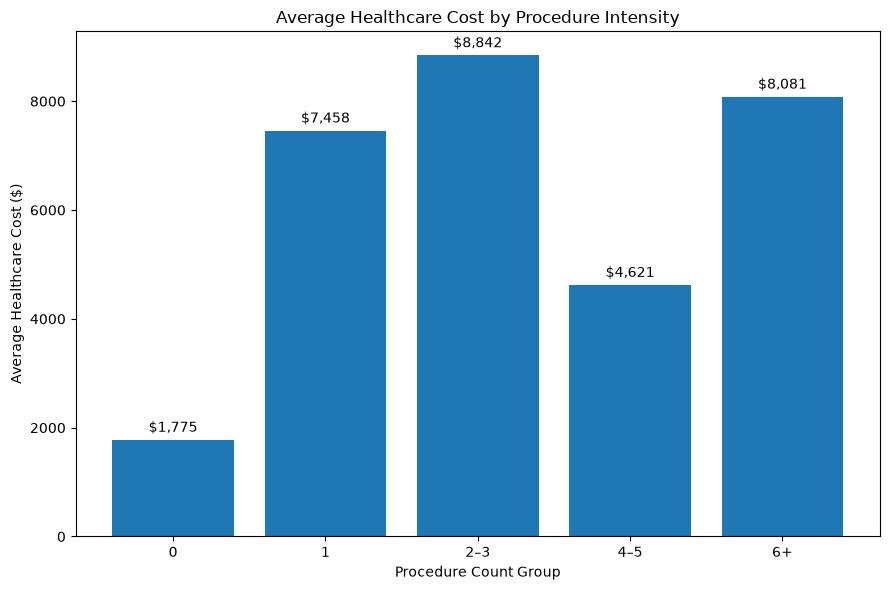

In [34]:
# Q3 Visualization
# Average Healthcare Cost by Procedure Intensity Group

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.bar(
    procedure_group_summary["procedure_group"].astype(str),
    procedure_group_summary["average_cost"]
)

plt.xlabel("Procedure Count Group")
plt.ylabel("Average Healthcare Cost ($)")
plt.title("Average Healthcare Cost by Procedure Intensity")

for i, value in enumerate(procedure_group_summary["average_cost"]):
    plt.text(
        i,
        value + 150,
        f"${value:,.0f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [35]:
# Q4 — Step 1
# High-Cost vs Other Encounters: Clinical Utilization

utilization_features_q4 = [
    "procedure_count",
    "medication_count",
    "condition_count",
    "careplan_count",
    "observation_count",
    "imaging_study_count",
    "device_count",
    "supply_count"
]

high_cost_utilization = (
    master.groupby("HIGH_COST_FLAG")[utilization_features_q4]
    .agg(["mean", "median"])
)

print("Clinical Utilization: High-Cost vs Other Encounters")
display(high_cost_utilization)

Clinical Utilization: High-Cost vs Other Encounters


procedure_count        medication_count        condition_count  \
                          mean median             mean median            mean   
HIGH_COST_FLAG                                                                  
False                 1.267011    0.0         0.918809    0.0        0.616002   
True                 10.947967   20.0         0.855285    0.0        0.998374   

                      careplan_count        observation_count         \
               median           mean median              mean median   
HIGH_COST_FLAG                                                         
False             0.0       0.057919    0.0          8.168349    0.0   
True              1.0       0.661789    1.0          3.639024    0.0   

               imaging_study_count        device_count        supply_count  \
                              mean median         mean median         mean   
HIGH_COST_FLAG                                                               
False                     0.015121    0.0     0.000707    0.0     0.024407   
True                      0.000000    0.0     0.074797    0.0     0.143089   

                       
               median  
HIGH_COST_FLAG         
False             0.0  
True              0.0

In [36]:
# Q4 — Step 2
# High-Cost Encounters by Encounter Type

high_cost_by_type = (
    master.groupby("ENCOUNTERCLASS")
    .agg(
        total_encounters=("Id", "count"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

high_cost_by_type["high_cost_rate"] = (
    high_cost_by_type["high_cost_encounters"]
    / high_cost_by_type["total_encounters"]
    * 100
)

high_cost_by_type = high_cost_by_type.sort_values(
    "high_cost_rate",
    ascending=False
)

print("High-Cost Encounters by Encounter Type")
display(high_cost_by_type)

High-Cost Encounters by Encounter Type


,ENCOUNTERCLASS,total_encounters,high_cost_encounters,average_cost,high_cost_rate
0,ambulatory,20124,454,6524.192984,2.256013
1,emergency,2168,46,7926.408824,2.121771
4,urgentcare,2564,26,5798.274797,1.014041
2,inpatient,1728,9,8765.999421,0.520833
3,outpatient,10837,43,2827.510556,0.396789
5,wellness,24038,37,1909.491582,0.153923


In [37]:
# Q4 — Step 3
# High-Cost Encounters by Payer

high_cost_by_payer = (
    master.groupby("PAYER_NAME")
    .agg(
        total_encounters=("Id", "count"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

high_cost_by_payer["high_cost_rate"] = (
    high_cost_by_payer["high_cost_encounters"]
    / high_cost_by_payer["total_encounters"]
    * 100
)

high_cost_by_payer = high_cost_by_payer.sort_values(
    "high_cost_rate",
    ascending=False
)

print("High-Cost Encounters by Payer")
display(high_cost_by_payer)

High-Cost Encounters by Payer


,PAYER_NAME,total_encounters,high_cost_encounters,average_cost,high_cost_rate
6,Medicaid,5283,98,4915.015557,1.855007
8,NO_INSURANCE,13620,159,7455.913347,1.167401
1,Anthem,5532,61,2954.560575,1.102675
3,Cigna Health,5100,52,2882.309949,1.019608
2,Blue Cross Blue Shield,5950,57,2994.735706,0.957983
0,Aetna,5767,53,2777.263102,0.919022
9,UnitedHealthcare,5247,44,2639.839857,0.838574
5,Humana,5635,38,2558.691892,0.674357
7,Medicare,8482,50,3812.771399,0.589484
4,Dual Eligible,843,3,2407.238387,0.355872


In [38]:
# Q4 — Step 4
# Procedure Intensity: High-Cost vs Other

procedure_high_cost = (
    master.groupby("HIGH_COST_FLAG")
    .agg(
        encounter_count=("Id", "count"),
        average_procedures=("procedure_count", "mean"),
        median_procedures=("procedure_count", "median"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        total_cost=("TOTAL_CLAIM_COST", "sum")
    )
    .reset_index()
)

procedure_high_cost["HIGH_COST_FLAG"] = (
    procedure_high_cost["HIGH_COST_FLAG"]
    .map({True: "High-Cost", False: "Other"})
)

print("Procedure Intensity: High-Cost vs Other")
display(procedure_high_cost)

Procedure Intensity: High-Cost vs Other


,HIGH_COST_FLAG,encounter_count,average_procedures,median_procedures,average_cost,total_cost
0,Other,60844,1.267011,0.0,3476.310924,2.115127e+08
1,High-Cost,615,10.947967,20.0,70766.123902,4.352117e+07


In [39]:
# Q4 — Step 5
# High-Cost Rate by Procedure Intensity Group

high_cost_procedure_group = (
    master.groupby("procedure_group", observed=False)
    .agg(
        encounter_count=("Id", "count"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

high_cost_procedure_group["high_cost_rate"] = (
    high_cost_procedure_group["high_cost_encounters"]
    / high_cost_procedure_group["encounter_count"]
    * 100
)

print("High-Cost Rate by Procedure Intensity Group")
display(high_cost_procedure_group)

High-Cost Rate by Procedure Intensity Group


,procedure_group,encounter_count,high_cost_encounters,average_cost,high_cost_rate
0,0,35605,196,1774.833619,0.550484
1,1,10746,36,7457.679775,0.335008
2,2–3,5609,28,8841.896589,0.499198
3,4–5,4235,12,4621.145523,0.283353
4,6+,5264,343,8080.528298,6.515957


In [40]:
# Q4 — Step 6
# Overall High-Cost Segment Summary

high_cost_summary = {
    "Total Encounters": len(master),
    "High-Cost Encounters": int(master["HIGH_COST_FLAG"].sum()),
    "High-Cost Rate (%)": master["HIGH_COST_FLAG"].mean() * 100,
    "High-Cost Total Cost": master.loc[
        master["HIGH_COST_FLAG"], "TOTAL_CLAIM_COST"
    ].sum(),
    "High-Cost Average Cost": master.loc[
        master["HIGH_COST_FLAG"], "TOTAL_CLAIM_COST"
    ].mean(),
    "Other Average Cost": master.loc[
        ~master["HIGH_COST_FLAG"], "TOTAL_CLAIM_COST"
    ].mean()
}

print("High-Cost Segment Summary")

for key, value in high_cost_summary.items():
    if "Cost" in key:
        print(f"{key}: ${value:,.2f}")
    elif "%" in key:
        print(f"{key}: {value:.2f}%")
    else:
        print(f"{key}: {value:,}")

High-Cost Segment Summary
Total Encounters: 61,459
High-Cost Encounters: $615.00
High-Cost Rate (%): $1.00
High-Cost Total Cost: $43,521,166.20
High-Cost Average Cost: $70,766.12
Other Average Cost: $3,476.31


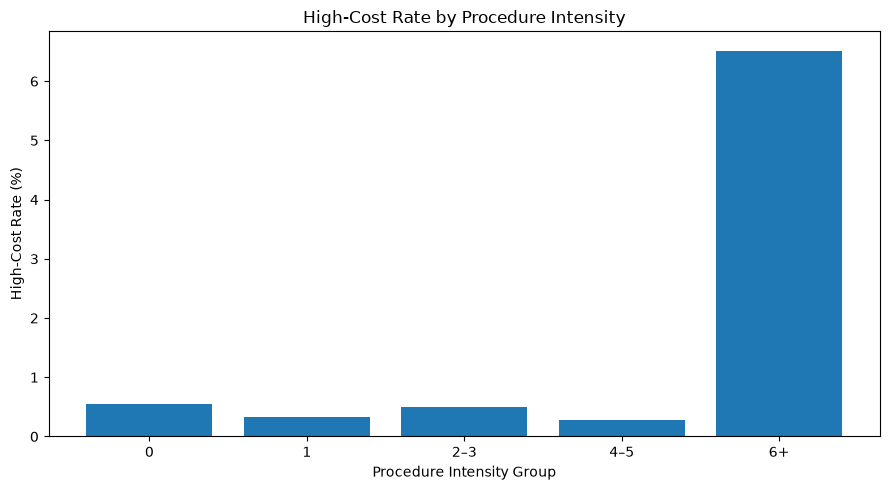

In [41]:
# Q4 — Visualization
# High-Cost Rate by Procedure Intensity

procedure_highcost_rate = (
    master.groupby("procedure_group")
    .agg(
        total_encounters=("HIGH_COST_FLAG", "size"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum")
    )
    .reset_index()
)

procedure_highcost_rate["high_cost_rate"] = (
    procedure_highcost_rate["high_cost_encounters"]
    / procedure_highcost_rate["total_encounters"]
    * 100
)

plt.figure(figsize=(9, 5))

plt.bar(
    procedure_highcost_rate["procedure_group"],
    procedure_highcost_rate["high_cost_rate"]
)

plt.xlabel("Procedure Intensity Group")
plt.ylabel("High-Cost Rate (%)")
plt.title("High-Cost Rate by Procedure Intensity")

plt.tight_layout()
plt.show()

In [42]:
# Q5 — Step 1
# Overall utilization distribution

utilization_cols = [
    "procedure_count",
    "imaging_study_count",
    "observation_count",
    "medication_count",
    "careplan_count",
    "condition_count",
    "device_count",
    "supply_count"
]

utilization_summary = master[utilization_cols].describe().T[
    ["count", "mean", "50%", "75%", "max"]
]

print("Overall Utilization Summary")
display(utilization_summary)

Overall Utilization Summary


,count,mean,50%,75%,max
procedure_count,61459.0,1.363885,0.0,1.0,27.0
imaging_study_count,61459.0,0.014969,0.0,0.0,1.0
observation_count,61459.0,8.123025,0.0,9.0,678.0
medication_count,61459.0,0.918173,0.0,1.0,13.0
careplan_count,61459.0,0.063961,0.0,0.0,2.0
condition_count,61459.0,0.619828,0.0,1.0,13.0
device_count,61459.0,0.001448,0.0,0.0,12.0
supply_count,61459.0,0.025594,0.0,0.0,88.0


In [43]:
# Q5 — Step 2
# Procedure repetition / intensity

procedure_repeat = (
    master.groupby("procedure_count")
    .agg(
        encounter_count=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

procedure_repeat = procedure_repeat.sort_values(
    "procedure_count",
    ascending=False
)

display(procedure_repeat.head(15))

,procedure_count,encounter_count,total_cost,average_cost
23,27,4,93212.08,23303.020000
22,26,1,77.49,77.490000
21,25,4,87245.78,21811.445000
20,23,5,191962.24,38392.448000
19,22,3,419999.17,139999.723333
18,21,10,505741.46,50574.146000
17,20,307,20711080.18,67462.801889
16,19,2,35049.85,17524.925000
15,17,1,17181.17,17181.170000
14,15,1,17348.50,17348.500000


In [44]:
# Q5 — Step 3
# Imaging utilization patterns

imaging_repeat = (
    master.groupby("imaging_study_count")
    .agg(
        encounter_count=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

imaging_repeat = imaging_repeat.sort_values(
    "imaging_study_count",
    ascending=False
)

display(imaging_repeat.head(15))

,imaging_study_count,encounter_count,total_cost,average_cost
1,1,920,8.508929e+06,9248.836402
0,0,60539,2.465249e+08,4072.166679


In [45]:
# Q5 — Step 4
# High procedure utilization indicator

master["HIGH_PROCEDURE_UTILIZATION"] = (
    master["procedure_count"] >= 6
)

high_utilization_summary = (
    master.groupby("HIGH_PROCEDURE_UTILIZATION")
    .agg(
        encounter_count=("Id", "count"),
        average_procedures=("procedure_count", "mean"),
        average_imaging=("imaging_study_count", "mean"),
        average_observations=("observation_count", "mean"),
        average_medications=("medication_count", "mean"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        total_cost=("TOTAL_CLAIM_COST", "sum")
    )
    .reset_index()
)

display(high_utilization_summary)

,HIGH_PROCEDURE_UTILIZATION,encounter_count,average_procedures,average_imaging,average_observations,average_medications,average_cost,total_cost
0,False,56195,0.776866,0.015891,5.165477,0.833989,3781.438333,2.124979e+08
1,True,5264,7.630509,0.005129,39.695859,1.816869,8080.528298,4.253590e+07


In [46]:
# Q5 — Step 5
# High utilization vs high-cost overlap

utilization_highcost = pd.crosstab(
    master["HIGH_PROCEDURE_UTILIZATION"],
    master["HIGH_COST_FLAG"],
    margins=True
)

print("High Procedure Utilization vs High-Cost Encounters")
display(utilization_highcost)

High Procedure Utilization vs High-Cost Encounters


HIGH_COST_FLAG,False,True,All
HIGH_PROCEDURE_UTILIZATION,,,
False,55923,272,56195
True,4921,343,5264
All,60844,615,61459


In [47]:
# Q5 — Step 6
# High-cost rate among high-utilization encounters

utilization_cost_rate = (
    master.groupby("HIGH_PROCEDURE_UTILIZATION")
    .agg(
        total_encounters=("Id", "count"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

utilization_cost_rate["high_cost_rate"] = (
    utilization_cost_rate["high_cost_encounters"]
    / utilization_cost_rate["total_encounters"]
    * 100
)

display(utilization_cost_rate)

,HIGH_PROCEDURE_UTILIZATION,total_encounters,high_cost_encounters,total_cost,average_cost,high_cost_rate
0,False,56195,272,2.124979e+08,3781.438333,0.484029
1,True,5264,343,4.253590e+07,8080.528298,6.515957


In [48]:
# Q5 — Step 7
# Combined utilization signal

master["MULTIPLE_UTILIZATION_SIGNAL"] = (
    (master["procedure_count"] >= 6) |
    (master["imaging_study_count"] >= 2) |
    (master["medication_count"] >= 4) |
    (master["careplan_count"] >= 2)
)

combined_utilization = (
    master.groupby("MULTIPLE_UTILIZATION_SIGNAL")
    .agg(
        encounter_count=("Id", "count"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum")
    )
    .reset_index()
)

combined_utilization["high_cost_rate"] = (
    combined_utilization["high_cost_encounters"]
    / combined_utilization["encounter_count"]
    * 100
)

display(combined_utilization)

,MULTIPLE_UTILIZATION_SIGNAL,encounter_count,average_cost,total_cost,high_cost_encounters,high_cost_rate
0,False,53958,3565.846889,1.924060e+08,225,0.416991
1,True,7501,8349.268319,6.262786e+07,390,5.199307


In [49]:
# Q5 — Step 8
# Final potential avoidable-utilization summary

q5_summary = {
    "Total Encounters": len(master),

    "High Procedure Utilization Encounters": int(
        master["HIGH_PROCEDURE_UTILIZATION"].sum()
    ),

    "High Procedure Utilization Rate (%)": (
        master["HIGH_PROCEDURE_UTILIZATION"].mean() * 100
    ),

    "High Procedure Utilization Total Cost": master.loc[
        master["HIGH_PROCEDURE_UTILIZATION"],
        "TOTAL_CLAIM_COST"
    ].sum(),

    "High Procedure Utilization Average Cost": master.loc[
        master["HIGH_PROCEDURE_UTILIZATION"],
        "TOTAL_CLAIM_COST"
    ].mean(),

    "High-Cost Encounters Within High Procedure Utilization": int(
        (
            master["HIGH_PROCEDURE_UTILIZATION"]
            & master["HIGH_COST_FLAG"]
        ).sum()
    )
}

print("Q5 — Potential Avoidable Utilization Summary")

for key, value in q5_summary.items():

    if "Cost" in key:
        print(f"{key}: ${value:,.2f}")

    elif "%" in key:
        print(f"{key}: {value:.2f}%")

    else:
        print(f"{key}: {value:,}")

Q5 — Potential Avoidable Utilization Summary
Total Encounters: 61,459
High Procedure Utilization Encounters: 5,264
High Procedure Utilization Rate (%): 8.57%
High Procedure Utilization Total Cost: $42,535,900.96
High Procedure Utilization Average Cost: $8,080.53
High-Cost Encounters Within High Procedure Utilization: $343.00


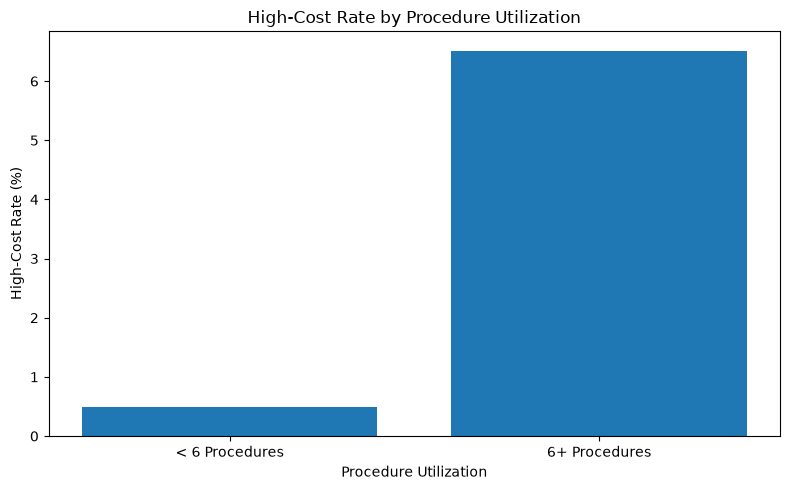

In [50]:
# Q5 — Visualization
# High-Cost Rate by Procedure Utilization Level

plot_data = (
    master.groupby("HIGH_PROCEDURE_UTILIZATION")
    .agg(
        total_encounters=("Id", "count"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum")
    )
    .reset_index()
)

plot_data["high_cost_rate"] = (
    plot_data["high_cost_encounters"]
    / plot_data["total_encounters"]
    * 100
)

plot_data["utilization_group"] = plot_data[
    "HIGH_PROCEDURE_UTILIZATION"
].map({
    False: "< 6 Procedures",
    True: "6+ Procedures"
})

plt.figure(figsize=(8, 5))

plt.bar(
    plot_data["utilization_group"],
    plot_data["high_cost_rate"]
)

plt.xlabel("Procedure Utilization")
plt.ylabel("High-Cost Rate (%)")
plt.title("High-Cost Rate by Procedure Utilization")

plt.tight_layout()
plt.show()

In [51]:
# Q6 — Step 1
# Provider-level cost and utilization summary

provider_summary = (
    master.groupby(["PROVIDER", "PROVIDER_UTILIZATION"])
    .agg(
        encounter_count=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        median_cost=("TOTAL_CLAIM_COST", "median"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum")
    )
    .reset_index()
)

provider_summary["high_cost_rate"] = (
    provider_summary["high_cost_encounters"]
    / provider_summary["encounter_count"]
    * 100
)

provider_summary = provider_summary.sort_values(
    "encounter_count",
    ascending=False
)

print("Provider-Level Cost Summary")

display(provider_summary.head(20))

Provider-Level Cost Summary


,PROVIDER,PROVIDER_UTILIZATION,encounter_count,total_cost,average_cost,median_cost,high_cost_encounters,high_cost_rate
293,43b6d00b-7643-36f8-8043-456d4eda39eb,3409,2184,6599341.65,3021.676580,884.54,15,0.686813
757,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,3954,1477,7717062.34,5224.822167,129.16,27,1.828030
1096,faa87618-81eb-3ac8-923b-bf203be11e67,2238,1105,6299498.08,5700.903240,358.53,20,1.809955
41,0bab5325-491c-326f-b1af-c28c8e4559f6,2595,1028,5240393.64,5097.659183,129.16,19,1.848249
250,3aade15e-5333-3c4e-86c5-aab3511bc8e8,2877,1020,6168896.27,6047.937520,594.14,21,2.058824
397,581cc2bd-9005-3008-8abb-299f40d36ca5,2706,1010,7111881.18,7041.466515,645.81,25,2.475248
865,c4d2ed7d-e1b3-37e2-82f9-b21046309ba4,2673,1000,5177101.78,5177.101780,594.14,10,1.000000
1060,f2ee2f6a-476a-3603-9848-b5773334fc00,1983,962,2642916.63,2747.314584,129.16,7,0.727651
398,584a32a8-2fc6-3c4f-947a-6b2c80851a1d,3852,941,5073541.12,5391.648374,269.68,21,2.231668
1104,fc897c25-b2ee-30c5-a945-d0eb13a1f96e,3111,877,5616714.69,6404.463729,269.68,14,1.596351


In [52]:
# Q6 — Step 2
# Providers with at least 100 encounters

provider_100 = provider_summary[
    provider_summary["encounter_count"] >= 100
].copy()

print("Providers with at least 100 encounters:",
      len(provider_100))

display(
    provider_100.sort_values(
        "average_cost",
        ascending=False
    ).head(20)
)

Providers with at least 100 encounters: 86


,PROVIDER,PROVIDER_UTILIZATION,encounter_count,total_cost,average_cost,median_cost,high_cost_encounters,high_cost_rate
908,ce615fe9-f785-3bbc-ba96-43c329746491,309,135,3690668.34,27338.284000,26977.860,6,4.444444
531,7a112976-6ab3-3811-86bc-ad86d1928fa5,522,192,4861869.92,25322.239167,26821.455,8,4.166667
438,62c53dbf-0f4e-3716-9bb5-cba7e411d7a4,694,579,7773134.39,13425.102573,1657.770,20,3.454231
137,2023a799-2651-317f-942e-af7d42ced2d9,481,182,2004804.41,11015.408846,10273.645,9,4.945055
484,701f23b0-fe1c-31b9-acf6-3bbe2b173716,1692,716,7415380.54,10356.676732,594.140,14,1.955307
857,c389231c-52b6-30d4-a8a9-002f09992142,466,232,2323639.34,10015.686810,8177.465,9,3.879310
900,ccc1c3fd-3418-3658-9325-3cc6c6a085c2,740,664,6497523.44,9785.426867,1142.035,16,2.409639
780,b496084f-cadd-3edc-bfdf-4ef1ace0af58,1071,551,5234289.20,9499.617423,129.160,9,1.633394
697,9f529022-166f-3db4-9f92-ff1ba11ee565,747,365,3348478.25,9173.913014,8939.180,6,1.643836
794,b7ccd823-5152-3c05-903b-7058f518495e,576,244,2104156.57,8623.592500,8526.440,2,0.819672


In [53]:
# Q6 — Step 3
# Top providers by total healthcare cost

provider_total_cost = provider_100.sort_values(
    "total_cost",
    ascending=False
)

display(
    provider_total_cost[
        [
            "PROVIDER",
            "encounter_count",
            "total_cost",
            "average_cost",
            "median_cost",
            "high_cost_encounters",
            "high_cost_rate"
        ]
    ].head(20)
)

,PROVIDER,encounter_count,total_cost,average_cost,median_cost,high_cost_encounters,high_cost_rate
438,62c53dbf-0f4e-3716-9bb5-cba7e411d7a4,579,7773134.39,13425.102573,1657.770,20,3.454231
757,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,1477,7717062.34,5224.822167,129.160,27,1.828030
484,701f23b0-fe1c-31b9-acf6-3bbe2b173716,716,7415380.54,10356.676732,594.140,14,1.955307
397,581cc2bd-9005-3008-8abb-299f40d36ca5,1010,7111881.18,7041.466515,645.810,25,2.475248
293,43b6d00b-7643-36f8-8043-456d4eda39eb,2184,6599341.65,3021.676580,884.540,15,0.686813
900,ccc1c3fd-3418-3658-9325-3cc6c6a085c2,664,6497523.44,9785.426867,1142.035,16,2.409639
809,bb49afa2-3d8a-306c-a06e-a1715dd71af8,835,6495903.15,7779.524731,2044.350,11,1.317365
1096,faa87618-81eb-3ac8-923b-bf203be11e67,1105,6299498.08,5700.903240,358.530,20,1.809955
250,3aade15e-5333-3c4e-86c5-aab3511bc8e8,1020,6168896.27,6047.937520,594.140,21,2.058824
738,aa2c2d64-bf7c-3eba-af47-ea9b5794c86e,765,6033325.07,7886.699438,645.810,33,4.313725


In [54]:
# Q6 — Step 4
# Provider utilization and cost relationship

provider_util_cost_corr = provider_100[
    ["PROVIDER_UTILIZATION", "average_cost"]
].corr().iloc[0, 1]

print(
    f"Correlation between provider utilization and "
    f"average encounter cost: {provider_util_cost_corr:.4f}"
)

display(
    provider_100[
        [
            "PROVIDER",
            "PROVIDER_UTILIZATION",
            "encounter_count",
            "average_cost"
        ]
    ].sort_values(
        "average_cost",
        ascending=False
    ).head(20)
)

Correlation between provider utilization and average encounter cost: 0.0863


,PROVIDER,PROVIDER_UTILIZATION,encounter_count,average_cost
908,ce615fe9-f785-3bbc-ba96-43c329746491,309,135,27338.284000
531,7a112976-6ab3-3811-86bc-ad86d1928fa5,522,192,25322.239167
438,62c53dbf-0f4e-3716-9bb5-cba7e411d7a4,694,579,13425.102573
137,2023a799-2651-317f-942e-af7d42ced2d9,481,182,11015.408846
484,701f23b0-fe1c-31b9-acf6-3bbe2b173716,1692,716,10356.676732
857,c389231c-52b6-30d4-a8a9-002f09992142,466,232,10015.686810
900,ccc1c3fd-3418-3658-9325-3cc6c6a085c2,740,664,9785.426867
780,b496084f-cadd-3edc-bfdf-4ef1ace0af58,1071,551,9499.617423
697,9f529022-166f-3db4-9f92-ff1ba11ee565,747,365,9173.913014
794,b7ccd823-5152-3c05-903b-7058f518495e,576,244,8623.592500


In [55]:
# Q6 — Step 5
# Organization-level cost and utilization summary

organization_summary = (
    master.groupby("ORGANIZATION_NAME")
    .agg(
        encounter_count=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        median_cost=("TOTAL_CLAIM_COST", "median"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum")
    )
    .reset_index()
)

organization_summary["high_cost_rate"] = (
    organization_summary["high_cost_encounters"]
    / organization_summary["encounter_count"]
    * 100
)

organization_summary = organization_summary.sort_values(
    "encounter_count",
    ascending=False
)

print("Organization-Level Cost Summary")

display(organization_summary.head(20))

Organization-Level Cost Summary


,ORGANIZATION_NAME,encounter_count,total_cost,average_cost,median_cost,high_cost_encounters,high_cost_rate
202,LAHEY HOSPITAL & MEDICAL CENTER BURLINGTON,2184,6599341.65,3021.676580,884.54,15,0.686813
275,NORTH SHORE MEDICAL CENTER -,1477,7717062.34,5224.822167,129.16,27,1.828030
163,HALLMARK HEALTH SYSTEM,1105,6299498.08,5700.903240,358.53,20,1.809955
38,BETH ISRAEL DEACONESS HOSPITAL - PLYMOUTH,1028,5240393.64,5097.659183,129.16,19,1.848249
250,MOUNT AUBURN HOSPITAL,1020,6168896.27,6047.937520,594.14,21,2.058824
65,CAMBRIDGE HEALTH ALLIANCE,1010,7111881.18,7041.466515,645.81,25,2.475248
248,MORTON HOSPITAL,1000,5177101.78,5177.101780,594.14,10,1.000000
913,SOUTHCOAST HOSPITAL GROUP INC,962,2642916.63,2747.314584,129.16,7,0.727651
209,LOWELL GENERAL HOSPITAL,941,5073541.12,5391.648374,269.68,21,2.231668
131,FALMOUTH HOSPITAL,877,5616714.69,6404.463729,269.68,14,1.596351


In [56]:
# Q6 — Step 6
# Organizations with at least 100 encounters

organization_100 = organization_summary[
    organization_summary["encounter_count"] >= 100
].copy()

print(
    "Organizations with at least 100 encounters:",
    len(organization_100)
)

display(
    organization_100.sort_values(
        "average_cost",
        ascending=False
    ).head(20)
)

Organizations with at least 100 encounters: 94


,ORGANIZATION_NAME,encounter_count,total_cost,average_cost,median_cost,high_cost_encounters,high_cost_rate
133,FAMILY CARE MEDICAL CENTER / URGENT CARE PHYSI...,135,3690668.34,27338.284000,26977.860,6,4.444444
951,URGENT CARE MEDICAL CLINIC,298,4877106.60,16366.129530,15917.205,8,2.684564
955,VA Boston Healthcare System Jamaica Plain Campus,579,7773134.39,13425.102573,1657.770,20,3.454231
229,MASSACHUSETTS EYE AND EAR INFIRMARY -,182,2004804.41,11015.408846,10273.645,9,4.945055
895,SAINT ANNE'S HOSPITAL,716,7415380.54,10356.676732,594.140,14,1.955307
237,MERCY MEDICAL CTR,232,2323639.34,10015.686810,8177.465,9,3.879310
931,Springfield Outpatient Clinic,664,6497523.44,9785.426867,1142.035,16,2.409639
172,HAWTHORN MEDICAL URGENT CARE CENTER,551,5234289.20,9499.617423,129.160,9,1.633394
898,SHRINERS' HOSPITAL FOR CHILDREN (THE),365,3348478.25,9173.913014,8939.180,6,1.643836
72,CARNEY HOSPITAL,244,2104156.57,8623.592500,8526.440,2,0.819672


In [57]:
# Q6 — Step 7
# Providers with the largest number of high-cost encounters

provider_highcost = (
    provider_100[
        [
            "PROVIDER",
            "encounter_count",
            "high_cost_encounters",
            "high_cost_rate",
            "average_cost",
            "total_cost"
        ]
    ]
    .sort_values(
        "high_cost_encounters",
        ascending=False
    )
)

display(provider_highcost.head(20))

,PROVIDER,encounter_count,high_cost_encounters,high_cost_rate,average_cost,total_cost
738,aa2c2d64-bf7c-3eba-af47-ea9b5794c86e,765,33,4.313725,7886.699438,6033325.07
757,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,1477,27,1.828030,5224.822167,7717062.34
1068,f4d65590-22bd-3409-9734-71ffd19f4945,821,26,3.166870,6810.768258,5591640.74
397,581cc2bd-9005-3008-8abb-299f40d36ca5,1010,25,2.475248,7041.466515,7111881.18
250,3aade15e-5333-3c4e-86c5-aab3511bc8e8,1020,21,2.058824,6047.937520,6168896.27
398,584a32a8-2fc6-3c4f-947a-6b2c80851a1d,941,21,2.231668,5391.648374,5073541.12
1096,faa87618-81eb-3ac8-923b-bf203be11e67,1105,20,1.809955,5700.903240,6299498.08
438,62c53dbf-0f4e-3716-9bb5-cba7e411d7a4,579,20,3.454231,13425.102573,7773134.39
41,0bab5325-491c-326f-b1af-c28c8e4559f6,1028,19,1.848249,5097.659183,5240393.64
900,ccc1c3fd-3418-3658-9325-3cc6c6a085c2,664,16,2.409639,9785.426867,6497523.44


In [58]:
# Q6 — Step 8
# Final Provider / Organization Cost Efficiency Summary

q6_summary = {
    "Total Encounters": len(master),
    "Providers with 100+ Encounters": len(provider_100),
    "Organizations with 100+ Encounters": len(organization_100),
    "Highest Provider Average Cost": provider_100["average_cost"].max(),
    "Highest Organization Average Cost": organization_100["average_cost"].max(),
    "Highest Provider High-Cost Rate": provider_100["high_cost_rate"].max(),
    "Highest Organization High-Cost Rate": organization_100["high_cost_rate"].max(),
    "Provider Utilization vs Average Cost Correlation":
        provider_util_cost_corr
}

print("Q6 — Provider / Organization Cost Efficiency Summary")

for key, value in q6_summary.items():
    if "Correlation" in key:
        print(f"{key}: {value:.4f}")
    elif "Rate" in key:
        print(f"{key}: {value:.2f}%")
    elif "Cost" in key:
        print(f"{key}: ${value:,.2f}")
    else:
        print(f"{key}: {value:,}")

Q6 — Provider / Organization Cost Efficiency Summary
Total Encounters: 61,459
Providers with 100+ Encounters: 86
Organizations with 100+ Encounters: 94
Highest Provider Average Cost: $27,338.28
Highest Organization Average Cost: $27,338.28
Highest Provider High-Cost Rate: 4.95%
Highest Organization High-Cost Rate: 4.95%
Provider Utilization vs Average Cost Correlation: 0.0863


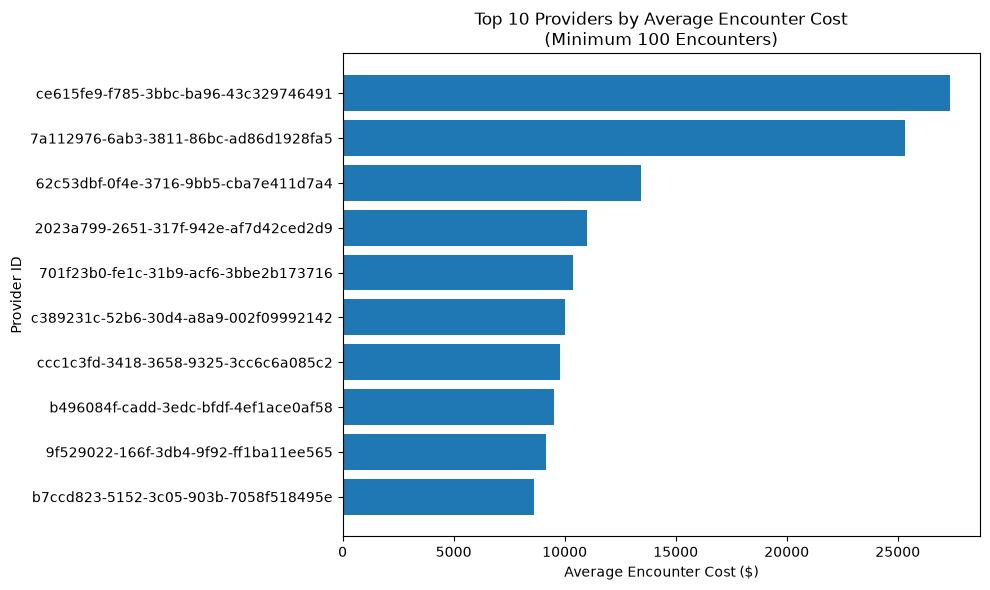

In [59]:
# Q6 — Visualization 1
# Top 10 Providers by Average Encounter Cost
# Providers with at least 100 encounters

top10_providers_avg = (
    provider_100
    .sort_values("average_cost", ascending=False)
    .head(10)
    .copy()
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_providers_avg["PROVIDER"].astype(str),
    top10_providers_avg["average_cost"]
)

plt.xlabel("Average Encounter Cost ($)")
plt.ylabel("Provider ID")
plt.title("Top 10 Providers by Average Encounter Cost\n(Minimum 100 Encounters)")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

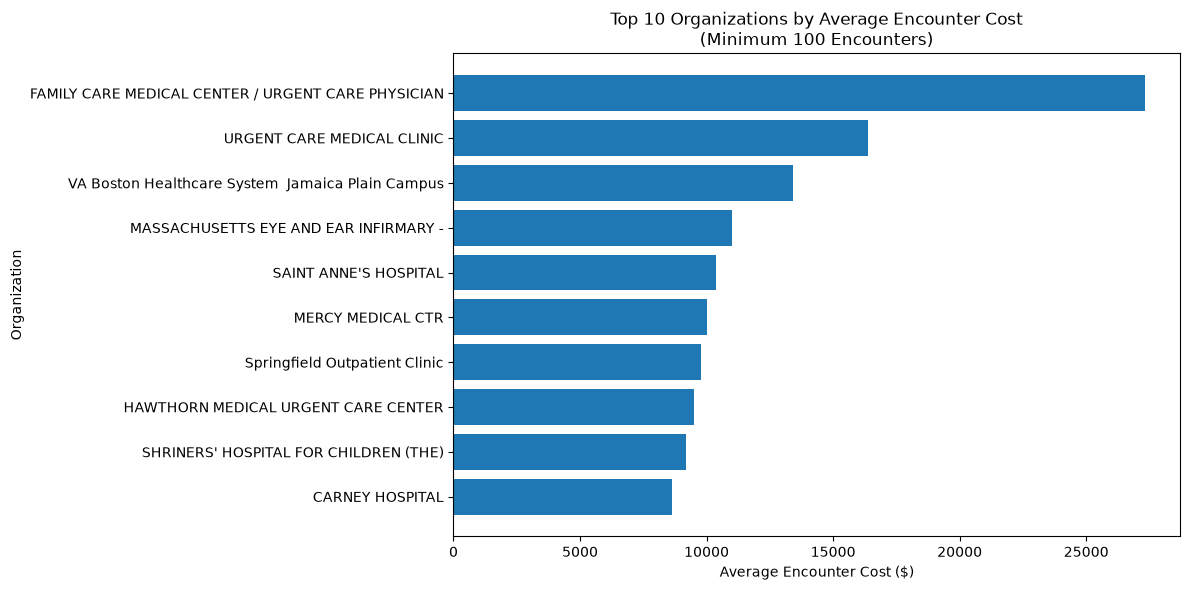

In [60]:
# Q6 — Visualization 2
# Top 10 Organizations by Average Encounter Cost
# Organizations with at least 100 encounters

top10_organizations_avg = (
    organization_100
    .sort_values("average_cost", ascending=False)
    .head(10)
    .copy()
)

plt.figure(figsize=(12, 6))

plt.barh(
    top10_organizations_avg["ORGANIZATION_NAME"],
    top10_organizations_avg["average_cost"]
)

plt.xlabel("Average Encounter Cost ($)")
plt.ylabel("Organization")
plt.title(
    "Top 10 Organizations by Average Encounter Cost\n"
    "(Minimum 100 Encounters)"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [61]:
payer_summary = (
    master.groupby("PAYER_NAME")
    .agg(
        encounter_count=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        median_cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("total_cost", ascending=False)
)

payer_summary["cost_share_pct"] = (
    payer_summary["total_cost"] / master["TOTAL_CLAIM_COST"].sum() * 100
)

payer_summary

,encounter_count,total_cost,average_cost,median_cost,cost_share_pct
PAYER_NAME,,,,,
NO_INSURANCE,13620,1.015495e+08,7455.913347,1304.83,39.818067
Medicare,8482,3.233993e+07,3812.771399,129.16,12.680642
Medicaid,5283,2.596603e+07,4915.015557,831.76,10.181405
Blue Cross Blue Shield,5950,1.781868e+07,2994.735706,786.33,6.986790
Anthem,5532,1.634463e+07,2954.560575,786.33,6.408808
Aetna,5767,1.601648e+07,2777.263102,786.33,6.280138
Cigna Health,5100,1.469978e+07,2882.309949,786.33,5.763855
Humana,5635,1.441823e+07,2558.691892,786.33,5.653457
UnitedHealthcare,5247,1.385124e+07,2639.839857,786.33,5.431138


In [62]:
payer_high_cost = (
    master.groupby("PAYER_NAME")
    .agg(
        encounter_count=("Id", "count"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
)

payer_high_cost["high_cost_rate_pct"] = (
    payer_high_cost["high_cost_encounters"]
    / payer_high_cost["encounter_count"] * 100
)

payer_high_cost = payer_high_cost.sort_values(
    "high_cost_rate_pct",
    ascending=False
)

payer_high_cost

,encounter_count,high_cost_encounters,average_cost,high_cost_rate_pct
PAYER_NAME,,,,
Medicaid,5283,98,4915.015557,1.855007
NO_INSURANCE,13620,159,7455.913347,1.167401
Anthem,5532,61,2954.560575,1.102675
Cigna Health,5100,52,2882.309949,1.019608
Blue Cross Blue Shield,5950,57,2994.735706,0.957983
Aetna,5767,53,2777.263102,0.919022
UnitedHealthcare,5247,44,2639.839857,0.838574
Humana,5635,38,2558.691892,0.674357
Medicare,8482,50,3812.771399,0.589484


In [63]:
coverage_summary = (
    master.groupby("PAYER_NAME")
    .agg(
        encounter_count=("Id", "count"),
        total_claim_cost=("TOTAL_CLAIM_COST", "sum"),
        total_payer_coverage=("PAYER_COVERAGE", "sum"),
        average_claim_cost=("TOTAL_CLAIM_COST", "mean"),
        average_payer_coverage=("PAYER_COVERAGE", "mean")
    )
)

coverage_summary["coverage_ratio_pct"] = (
    coverage_summary["total_payer_coverage"]
    / coverage_summary["total_claim_cost"] * 100
)

coverage_summary = coverage_summary.sort_values(
    "total_claim_cost",
    ascending=False
)

coverage_summary

,encounter_count,total_claim_cost,total_payer_coverage,average_claim_cost,average_payer_coverage,coverage_ratio_pct
PAYER_NAME,,,,,,
NO_INSURANCE,13620,1.015495e+08,0.00,7455.913347,0.000000,0.000000
Medicare,8482,3.233993e+07,25643264.46,3812.771399,3023.256833,79.292895
Medicaid,5283,2.596603e+07,24423140.77,4915.015557,4622.968156,94.058057
Blue Cross Blue Shield,5950,1.781868e+07,11570960.86,2994.735706,1944.699304,64.937260
Anthem,5532,1.634463e+07,2402.73,2954.560575,0.434333,0.014700
Aetna,5767,1.601648e+07,8466.79,2777.263102,1.468145,0.052863
Cigna Health,5100,1.469978e+07,5666.34,2882.309949,1.111047,0.038547
Humana,5635,1.441823e+07,2355.54,2558.691892,0.418020,0.016337
UnitedHealthcare,5247,1.385124e+07,4643.45,2639.839857,0.884972,0.033524


In [64]:
master["INSURANCE_STATUS"] = master["PAYER_NAME"].apply(
    lambda x: "No Insurance" if x == "NO_INSURANCE" else "Insured"
)

insurance_summary = (
    master.groupby("INSURANCE_STATUS")
    .agg(
        encounter_count=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        median_cost=("TOTAL_CLAIM_COST", "median")
    )
)

insurance_summary["cost_share_pct"] = (
    insurance_summary["total_cost"]
    / master["TOTAL_CLAIM_COST"].sum() * 100
)

insurance_summary

,encounter_count,total_cost,average_cost,median_cost,cost_share_pct
INSURANCE_STATUS,,,,,
Insured,47839,1.534843e+08,3208.350682,786.33,60.181933
No Insurance,13620,1.015495e+08,7455.913347,1304.83,39.818067


In [65]:
insurance_high_cost = (
    master.groupby("INSURANCE_STATUS")
    .agg(
        encounter_count=("Id", "count"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean")
    )
)

insurance_high_cost["high_cost_rate_pct"] = (
    insurance_high_cost["high_cost_encounters"]
    / insurance_high_cost["encounter_count"] * 100
)

insurance_high_cost

,encounter_count,high_cost_encounters,average_cost,high_cost_rate_pct
INSURANCE_STATUS,,,,
Insured,47839,456,3208.350682,0.953197
No Insurance,13620,159,7455.913347,1.167401


In [66]:
q7_summary = (
    master.groupby("PAYER_NAME")
    .agg(
        encounters=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum"),
        average_cost=("TOTAL_CLAIM_COST", "mean"),
        median_cost=("TOTAL_CLAIM_COST", "median"),
        high_cost_encounters=("HIGH_COST_FLAG", "sum"),
        payer_coverage=("PAYER_COVERAGE", "sum")
    )
)

q7_summary["cost_share_pct"] = (
    q7_summary["total_cost"]
    / master["TOTAL_CLAIM_COST"].sum() * 100
)

q7_summary["high_cost_rate_pct"] = (
    q7_summary["high_cost_encounters"]
    / q7_summary["encounters"] * 100
)

q7_summary = q7_summary.sort_values(
    "total_cost",
    ascending=False
)

q7_summary

,encounters,total_cost,average_cost,median_cost,high_cost_encounters,payer_coverage,cost_share_pct,high_cost_rate_pct
PAYER_NAME,,,,,,,,
NO_INSURANCE,13620,1.015495e+08,7455.913347,1304.83,159,0.00,39.818067,1.167401
Medicare,8482,3.233993e+07,3812.771399,129.16,50,25643264.46,12.680642,0.589484
Medicaid,5283,2.596603e+07,4915.015557,831.76,98,24423140.77,10.181405,1.855007
Blue Cross Blue Shield,5950,1.781868e+07,2994.735706,786.33,57,11570960.86,6.986790,0.957983
Anthem,5532,1.634463e+07,2954.560575,786.33,61,2402.73,6.408808,1.102675
Aetna,5767,1.601648e+07,2777.263102,786.33,53,8466.79,6.280138,0.919022
Cigna Health,5100,1.469978e+07,2882.309949,786.33,52,5666.34,5.763855,1.019608
Humana,5635,1.441823e+07,2558.691892,786.33,38,2355.54,5.653457,0.674357
UnitedHealthcare,5247,1.385124e+07,2639.839857,786.33,44,4643.45,5.431138,0.838574


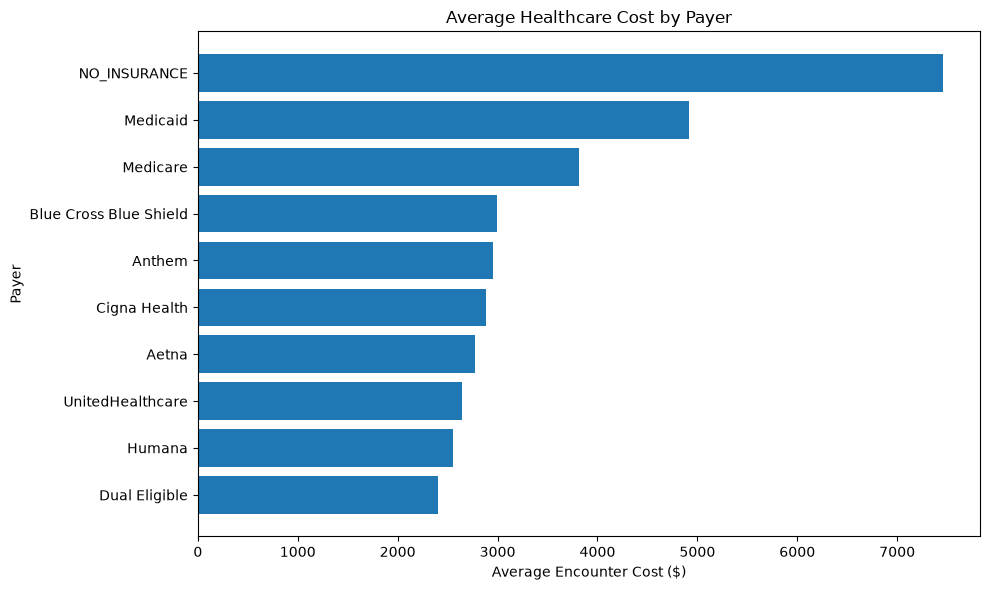

In [67]:
import matplotlib.pyplot as plt

plot_data = (
    payer_summary
    .sort_values("average_cost", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["average_cost"]
)

plt.xlabel("Average Encounter Cost ($)")
plt.ylabel("Payer")
plt.title("Average Healthcare Cost by Payer")

plt.tight_layout()
plt.show()

In [68]:
# Q8 - Step 1
# Create patient-level cost summary

patient_summary = (
    master.groupby("PATIENT")
    .agg(
        total_healthcare_cost=("TOTAL_CLAIM_COST", "sum"),
        encounter_count=("Id", "count"),
        average_encounter_cost=("TOTAL_CLAIM_COST", "mean"),
        median_encounter_cost=("TOTAL_CLAIM_COST", "median")
    )
    .reset_index()
)

print("Number of patients:", len(patient_summary))
print("\nPatient-level summary:")
display(patient_summary.head())

print("\nSummary statistics:")
display(patient_summary[
    [
        "total_healthcare_cost",
        "encounter_count",
        "average_encounter_cost",
        "median_encounter_cost"
    ]
].describe())

Number of patients: 1163

Patient-level summary:


,PATIENT,total_healthcare_cost,encounter_count,average_encounter_cost,median_encounter_cost
0,00126cb9-8460-4747-e302-c3609684531e,455251.08,60,7587.518000,2538.00
1,00209bf2-8e4d-06d1-82a4-daad02f25829,118448.38,76,1558.531316,786.33
2,00ae3b00-9500-efc1-2758-a93d3f77e650,50643.60,40,1266.090000,786.33
3,00c9ca99-6b9f-add4-8759-f7dfee6ea1a4,83707.35,47,1781.007447,786.33
4,0142b69f-57f0-9a08-4e2d-65a2b77fdea7,87542.21,41,2135.175854,786.33



Summary statistics:


,total_healthcare_cost,encounter_count,average_encounter_cost,median_encounter_cost
count,1.163000e+03,1163.000000,1163.000000,1163.000000
mean,2.192896e+05,52.845228,3356.022084,1676.020757
std,6.116074e+05,72.628805,3550.996138,2867.927429
min,9.193600e+02,2.000000,284.856536,77.490000
25%,2.120860e+04,21.000000,853.035918,645.810000
50%,8.370735e+04,40.000000,1752.209352,786.330000
75%,2.626197e+05,64.000000,4873.096843,1075.545000
max,1.319785e+07,1563.000000,25361.072692,26097.735000


In [69]:
# Q8 - Step 2
# Identify the top 1% highest-cost patients

patient_cost_threshold = patient_summary["total_healthcare_cost"].quantile(0.99)

patient_summary["HIGH_COST_PATIENT"] = (
    patient_summary["total_healthcare_cost"] >= patient_cost_threshold
)

high_cost_patients = patient_summary[
    patient_summary["HIGH_COST_PATIENT"]
].copy()

other_patients = patient_summary[
    ~patient_summary["HIGH_COST_PATIENT"]
].copy()

print("99th percentile patient cost threshold:",
      round(patient_cost_threshold, 2))

print("\nHigh-cost patients:", len(high_cost_patients))
print("Other patients:", len(other_patients))

print("\nHigh-cost patient statistics:")
display(
    high_cost_patients[
        [
            "total_healthcare_cost",
            "encounter_count",
            "average_encounter_cost",
            "median_encounter_cost"
        ]
    ].describe()
)

print("\nOther patient statistics:")
display(
    other_patients[
        [
            "total_healthcare_cost",
            "encounter_count",
            "average_encounter_cost",
            "median_encounter_cost"
        ]
    ].describe()
)

99th percentile patient cost threshold: 1111270.75

High-cost patients: 12
Other patients: 1151

High-cost patient statistics:


,total_healthcare_cost,encounter_count,average_encounter_cost,median_encounter_cost
count,1.200000e+01,12.000000,12.000000,12.000000
mean,3.722842e+06,343.583333,12272.117125,11968.555000
std,4.482337e+06,432.111193,6241.429719,7366.917092
min,1.121047e+06,88.000000,1281.807646,891.700000
25%,1.147777e+06,112.750000,9029.446156,8247.003750
50%,1.236103e+06,131.500000,10218.886822,11138.315000
75%,3.914835e+06,433.250000,15253.174198,14192.572500
max,1.319785e+07,1563.000000,24801.748398,26097.735000



Other patient statistics:


,total_healthcare_cost,encounter_count,average_encounter_cost,median_encounter_cost
count,1.151000e+03,1151.000000,1151.000000,1151.000000
mean,1.827626e+05,49.814075,3263.065402,1568.713710
std,2.374188e+05,51.504700,3395.637593,2583.557402
min,9.193600e+02,2.000000,284.856536,77.490000
25%,2.109449e+04,21.000000,850.427744,645.810000
50%,8.091152e+04,39.000000,1737.257308,786.330000
75%,2.509168e+05,62.500000,4605.321550,1067.370000
max,1.105279e+06,838.000000,25361.072692,19213.390000


In [70]:
# Q8 - Step 3
# Measure how much total healthcare spending is concentrated
# among the top 1% highest-cost patients

total_patient_spending = patient_summary["total_healthcare_cost"].sum()

high_cost_patient_spending = (
    high_cost_patients["total_healthcare_cost"].sum()
)

other_patient_spending = (
    other_patients["total_healthcare_cost"].sum()
)

high_cost_patient_spending_share = (
    high_cost_patient_spending / total_patient_spending * 100
)

other_patient_spending_share = (
    other_patient_spending / total_patient_spending * 100
)

print("Total healthcare spending:",
      round(total_patient_spending, 2))

print("\nTop 1% patient spending:",
      round(high_cost_patient_spending, 2))

print("Top 1% patient spending share:",
      round(high_cost_patient_spending_share, 2), "%")

print("\nOther patient spending:",
      round(other_patient_spending, 2))

print("Other patient spending share:",
      round(other_patient_spending_share, 2), "%")

print("\nAverage spending per top 1% patient:",
      round(
          high_cost_patient_spending / len(high_cost_patients),
          2
      ))

print("Average spending per other patient:",
      round(
          other_patient_spending / len(other_patients),
          2
      ))

Total healthcare spending: 255033828.08

Top 1% patient spending: 44674104.28
Top 1% patient spending share: 17.52 %

Other patient spending: 210359723.8
Other patient spending share: 82.48 %

Average spending per top 1% patient: 3722842.02
Average spending per other patient: 182762.57


In [71]:
# Q8 - Step 4
# Identify frequent healthcare users

frequent_user_threshold = patient_summary["encounter_count"].quantile(0.90)

patient_summary["FREQUENT_USER"] = (
    patient_summary["encounter_count"] >= frequent_user_threshold
)

frequent_users = patient_summary[
    patient_summary["FREQUENT_USER"]
].copy()

other_users = patient_summary[
    ~patient_summary["FREQUENT_USER"]
].copy()

print("90th percentile encounter-count threshold:",
      frequent_user_threshold)

print("\nFrequent users:", len(frequent_users))
print("Other users:", len(other_users))

print("\nFrequent-user statistics:")
display(
    frequent_users[
        [
            "total_healthcare_cost",
            "encounter_count",
            "average_encounter_cost",
            "median_encounter_cost"
        ]
    ].describe()
)

print("\nOther-user statistics:")
display(
    other_users[
        [
            "total_healthcare_cost",
            "encounter_count",
            "average_encounter_cost",
            "median_encounter_cost"
        ]
    ].describe()
)

90th percentile encounter-count threshold: 92.0

Frequent users: 119
Other users: 1044

Frequent-user statistics:


,total_healthcare_cost,encounter_count,average_encounter_cost,median_encounter_cost
count,1.190000e+02,119.000000,119.000000,119.000000
mean,7.487694e+05,173.277311,4294.345156,2905.099160
std,1.724218e+06,176.787574,4370.666777,4992.754162
min,5.262609e+04,92.000000,284.856536,77.490000
25%,1.636790e+05,106.000000,1053.883335,129.160000
50%,3.125166e+05,119.000000,2299.997778,786.330000
75%,8.939284e+05,143.500000,7186.292947,1446.785000
max,1.319785e+07,1563.000000,24801.748398,26097.735000



Other-user statistics:


,total_healthcare_cost,encounter_count,average_encounter_cost,median_encounter_cost
count,1.044000e+03,1044.000000,1044.000000,1044.000000
mean,1.589370e+05,39.117816,3249.067634,1535.924655
std,2.115829e+05,22.303462,3431.494539,2480.170055
min,9.193600e+02,2.000000,319.285833,77.490000
25%,1.903405e+04,20.000000,840.678731,645.810000
50%,6.763296e+04,35.000000,1732.977500,786.330000
75%,2.074716e+05,56.000000,4513.597490,1067.370000
max,1.240575e+06,91.000000,25361.072692,19213.390000


In [72]:
# Q8 - Step 5
# Measure spending concentration among frequent healthcare users

frequent_user_spending = (
    frequent_users["total_healthcare_cost"].sum()
)

other_user_spending = (
    other_users["total_healthcare_cost"].sum()
)

total_spending = patient_summary["total_healthcare_cost"].sum()

frequent_user_spending_share = (
    frequent_user_spending / total_spending * 100
)

other_user_spending_share = (
    other_user_spending / total_spending * 100
)

print("Total healthcare spending:",
      round(total_spending, 2))

print("\nFrequent-user spending:",
      round(frequent_user_spending, 2))

print("Frequent-user spending share:",
      round(frequent_user_spending_share, 2), "%")

print("\nOther-user spending:",
      round(other_user_spending, 2))

print("Other-user spending share:",
      round(other_user_spending_share, 2), "%")

print("\nAverage spending per frequent user:",
      round(
          frequent_user_spending / len(frequent_users),
          2
      ))

print("Average spending per other user:",
      round(
          other_user_spending / len(other_users),
          2
      ))

Total healthcare spending: 255033828.08

Frequent-user spending: 89103555.2
Frequent-user spending share: 34.94 %

Other-user spending: 165930272.88
Other-user spending share: 65.06 %

Average spending per frequent user: 748769.37
Average spending per other user: 158937.04


In [73]:
# Q8 - Step 6
# Measure overlap between frequent users and high-cost patients

high_cost_patient_ids = set(
    high_cost_patients["PATIENT"]
)

frequent_user_ids = set(
    frequent_users["PATIENT"]
)

overlap_ids = (
    high_cost_patient_ids.intersection(frequent_user_ids)
)

high_cost_only_ids = (
    high_cost_patient_ids - frequent_user_ids
)

frequent_only_ids = (
    frequent_user_ids - high_cost_patient_ids
)

print("Total high-cost patients:", len(high_cost_patient_ids))
print("Total frequent users:", len(frequent_user_ids))

print("\nPatients who are BOTH high-cost and frequent:",
      len(overlap_ids))

print("High-cost patients who are NOT frequent users:",
      len(high_cost_only_ids))

print("Frequent users who are NOT high-cost patients:",
      len(frequent_only_ids))

print("\nOverlap among high-cost patients:",
      round(
          len(overlap_ids) / len(high_cost_patient_ids) * 100,
          2
      ),
      "%")

print("Overlap among frequent users:",
      round(
          len(overlap_ids) / len(frequent_user_ids) * 100,
          2
      ),
      "%")



Total high-cost patients: 12
Total frequent users: 119

Patients who are BOTH high-cost and frequent: 11
High-cost patients who are NOT frequent users: 1
Frequent users who are NOT high-cost patients: 108

Overlap among high-cost patients: 91.67 %
Overlap among frequent users: 9.24 %


In [74]:
# Q8 - Step 7
# Create four patient-level cost/utilization segments

patient_summary["PATIENT_SEGMENT"] = "Not High-Cost + Not Frequent"

patient_summary.loc[
    (~patient_summary["HIGH_COST_PATIENT"]) &
    (patient_summary["FREQUENT_USER"]),
    "PATIENT_SEGMENT"
] = "Frequent + Not High-Cost"

patient_summary.loc[
    (patient_summary["HIGH_COST_PATIENT"]) &
    (~patient_summary["FREQUENT_USER"]),
    "PATIENT_SEGMENT"
] = "High-Cost + Not Frequent"

patient_summary.loc[
    (patient_summary["HIGH_COST_PATIENT"]) &
    (patient_summary["FREQUENT_USER"]),
    "PATIENT_SEGMENT"
] = "High-Cost + Frequent"

segment_summary = (
    patient_summary
    .groupby("PATIENT_SEGMENT")
    .agg(
        patient_count=("PATIENT", "count"),
        total_healthcare_cost=("total_healthcare_cost", "sum"),
        average_patient_cost=("total_healthcare_cost", "mean"),
        median_patient_cost=("total_healthcare_cost", "median"),
        average_encounters=("encounter_count", "mean"),
        average_encounter_cost=("average_encounter_cost", "mean")
    )
    .reset_index()
)

segment_summary["patient_share_pct"] = (
    segment_summary["patient_count"]
    / len(patient_summary) * 100
)

segment_summary["cost_share_pct"] = (
    segment_summary["total_healthcare_cost"]
    / patient_summary["total_healthcare_cost"].sum() * 100
)

segment_summary = segment_summary.sort_values(
    "total_healthcare_cost",
    ascending=False
)

display(segment_summary)

,PATIENT_SEGMENT,patient_count,total_healthcare_cost,average_patient_cost,median_patient_cost,average_encounters,average_encounter_cost,patient_share_pct,cost_share_pct
3,Not High-Cost + Not Frequent,1043,1.646897e+08,1.579000e+05,67594.11,39.070949,3238.666504,89.681857,64.575629
0,Frequent + Not High-Cost,108,4.567003e+07,4.228706e+05,268976.14,153.564815,3498.695499,9.286328,17.907439
1,High-Cost + Frequent,11,4.343353e+07,3.948503e+06,1231629.94,366.818182,12106.178155,0.945830,17.030497
2,High-Cost + Not Frequent,1,1.240575e+06,1.240575e+06,1240575.23,88.000000,14097.445795,0.085985,0.486436


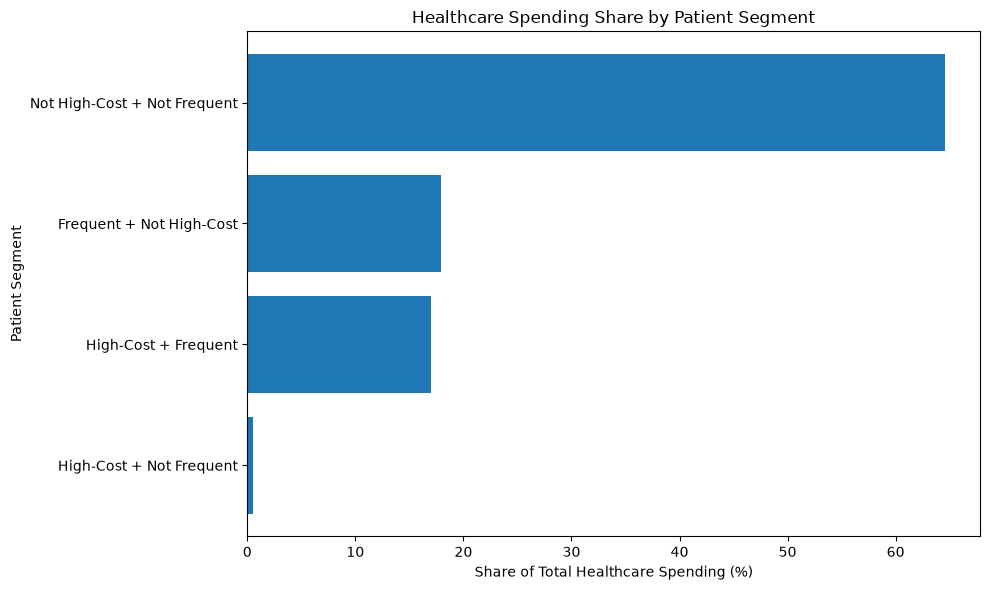

In [75]:
# Q8 - Step 8
# Visualization: Healthcare spending share by patient segment

import matplotlib.pyplot as plt

plot_data = segment_summary.sort_values(
    "cost_share_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["PATIENT_SEGMENT"],
    plot_data["cost_share_pct"]
)

plt.xlabel("Share of Total Healthcare Spending (%)")
plt.ylabel("Patient Segment")
plt.title("Healthcare Spending Share by Patient Segment")

plt.tight_layout()
plt.show()

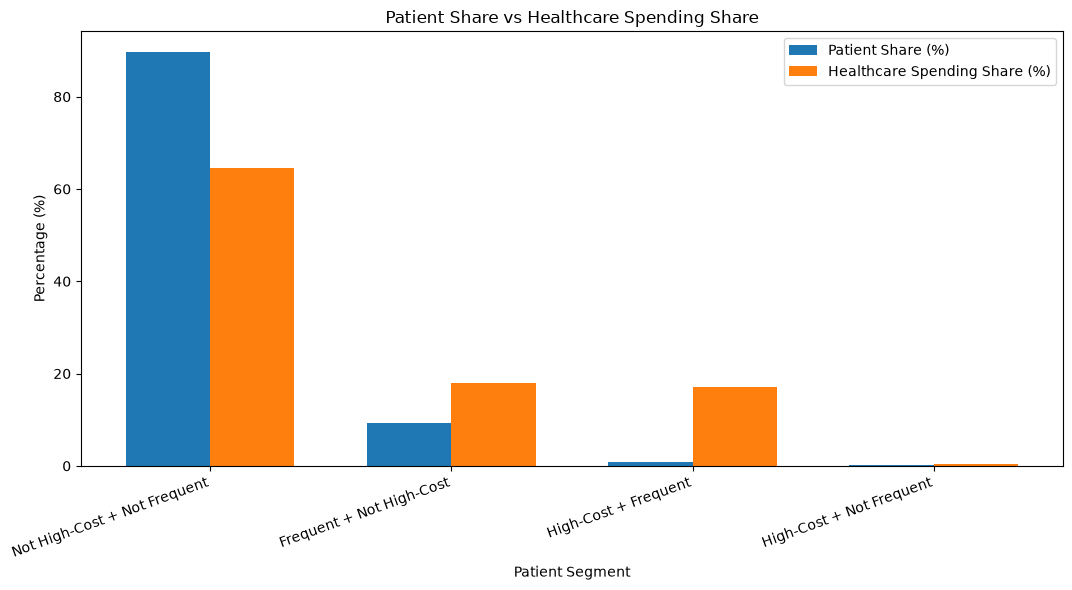

In [76]:
# Q8 - Visualization 2
# Patient Share vs Healthcare Spending Share

import matplotlib.pyplot as plt

plot_data = segment_summary.copy()

plt.figure(figsize=(11, 6))

x = range(len(plot_data))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    plot_data["patient_share_pct"],
    width=width,
    label="Patient Share (%)"
)

plt.bar(
    [i + width/2 for i in x],
    plot_data["cost_share_pct"],
    width=width,
    label="Healthcare Spending Share (%)"
)

plt.xlabel("Patient Segment")
plt.ylabel("Percentage (%)")
plt.title("Patient Share vs Healthcare Spending Share")

plt.xticks(
    list(x),
    plot_data["PATIENT_SEGMENT"],
    rotation=20,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

In [77]:
# Q9 - Step 1
# Check candidate cost-driver variables

q9_columns = [
    "TOTAL_CLAIM_COST",
    "ENCOUNTERCLASS",
    "AGE_AT_ENCOUNTER",
    "PATIENT_GENDER",
    "RACE",
    "ETHNICITY",
    "condition_count",
    "procedure_count",
    "medication_count",
    "immunization_count",
    "observation_count",
    "careplan_count",
    "device_count",
    "imaging_study_count",
    "supply_count",
    "PROVIDER_SPECIALITY",
    "PAYER_NAME"
]

q9_check = master[q9_columns].copy()

print("Q9 dataset shape:", q9_check.shape)

print("\nMissing values:")
display(q9_check.isna().sum())

print("\nData types:")
display(q9_check.dtypes)

print("\nSample:")
display(q9_check.head())

Q9 dataset shape: (61459, 17)

Missing values:


TOTAL_CLAIM_COST       0
ENCOUNTERCLASS         0
AGE_AT_ENCOUNTER       0
PATIENT_GENDER         0
RACE                   0
ETHNICITY              0
condition_count        0
procedure_count        0
medication_count       0
immunization_count     0
observation_count      0
careplan_count         0
device_count           0
imaging_study_count    0
supply_count           0
PROVIDER_SPECIALITY    0
PAYER_NAME             0
dtype: int64


Data types:


TOTAL_CLAIM_COST       float64
ENCOUNTERCLASS             str
AGE_AT_ENCOUNTER       float64
PATIENT_GENDER             str
RACE                       str
ETHNICITY                  str
condition_count          int64
procedure_count          int64
medication_count         int64
immunization_count       int64
observation_count        int64
careplan_count           int64
device_count             int64
imaging_study_count      int64
supply_count             int64
PROVIDER_SPECIALITY        str
PAYER_NAME                 str
dtype: object


Sample:


,TOTAL_CLAIM_COST,ENCOUNTERCLASS,AGE_AT_ENCOUNTER,PATIENT_GENDER,RACE,ETHNICITY,condition_count,procedure_count,medication_count,immunization_count,observation_count,careplan_count,device_count,imaging_study_count,supply_count,PROVIDER_SPECIALITY,PAYER_NAME
35318,1212.05,wellness,18.1,F,white,nonhispanic,3,0,1,0,0,1,0,0,0,GENERAL PRACTICE,NO_INSURANCE
35319,77.49,ambulatory,18.2,F,white,nonhispanic,0,0,1,0,0,0,0,0,0,GENERAL PRACTICE,NO_INSURANCE
35320,786.33,wellness,19.2,F,white,nonhispanic,1,0,2,0,0,0,0,0,0,GENERAL PRACTICE,NO_INSURANCE
35321,1497.66,wellness,20.2,F,white,nonhispanic,0,0,2,0,0,0,0,0,0,GENERAL PRACTICE,NO_INSURANCE
35322,1635.52,wellness,21.2,F,white,nonhispanic,1,0,2,0,0,0,0,0,0,GENERAL PRACTICE,NO_INSURANCE


In [78]:
# Q9 - Step 2
# Examine the distribution of healthcare cost

cost = q9_check["TOTAL_CLAIM_COST"]

print("Healthcare Cost Summary")
print("-" * 40)

print("Mean:", round(cost.mean(), 2))
print("Median:", round(cost.median(), 2))
print("Standard Deviation:", round(cost.std(), 2))
print("Minimum:", round(cost.min(), 2))
print("Maximum:", round(cost.max(), 2))

print("\nPercentiles:")
display(
    cost.quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
)

print("\nSkewness:", round(cost.skew(), 2))

print("\nZero-cost encounters:", (cost == 0).sum())
print("Positive-cost encounters:", (cost > 0).sum())

Healthcare Cost Summary
----------------------------------------
Mean: 4149.66
Median: 786.33
Standard Deviation: 10919.68
Minimum: 0.0
Maximum: 873646.19

Percentiles:


0.25      129.160
0.50      786.330
0.75     1625.890
0.90    14149.706
0.95    19045.437
0.99    45209.380
Name: TOTAL_CLAIM_COST, dtype: float64


Skewness: 19.32

Zero-cost encounters: 229
Positive-cost encounters: 61230


In [79]:
# Q9 - Step 3
# Prepare modeling dataset and log-transformed cost target

model_data = q9_check.copy()

# Remove provider specialty because it has only one unique value
model_data = model_data.drop(columns=["PROVIDER_SPECIALITY"])

# Create log-transformed healthcare cost
model_data["LOG_COST"] = np.log1p(
    model_data["TOTAL_CLAIM_COST"]
)

print("Modeling dataset shape:", model_data.shape)

print("\nColumns:")
print(model_data.columns.tolist())

print("\nLog-cost summary:")
display(model_data["LOG_COST"].describe())

print("\nZero-cost encounters retained:",
      (model_data["TOTAL_CLAIM_COST"] == 0).sum())

Modeling dataset shape: (61459, 17)

Columns:
['TOTAL_CLAIM_COST', 'ENCOUNTERCLASS', 'AGE_AT_ENCOUNTER', 'PATIENT_GENDER', 'RACE', 'ETHNICITY', 'condition_count', 'procedure_count', 'medication_count', 'immunization_count', 'observation_count', 'careplan_count', 'device_count', 'imaging_study_count', 'supply_count', 'PAYER_NAME', 'LOG_COST']

Log-cost summary:


count    61459.000000
mean         6.659202
std          1.861763
min          0.000000
25%          4.868764
50%          6.668647
75%          7.394425
max         13.680432
Name: LOG_COST, dtype: float64


Zero-cost encounters retained: 229


In [80]:
# Q9 - Step 4
# Prepare predictors using one-hot encoding

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "AGE_AT_ENCOUNTER",
    "condition_count",
    "procedure_count",
    "medication_count",
    "immunization_count",
    "observation_count",
    "careplan_count",
    "device_count",
    "imaging_study_count",
    "supply_count"
]

categorical_features = [
    "ENCOUNTERCLASS",
    "PATIENT_GENDER",
    "RACE",
    "ETHNICITY",
    "PAYER_NAME"
]

X = model_data[
    numeric_features + categorical_features
]

y = model_data["LOG_COST"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

X_encoded = preprocessor.fit_transform(X)

print("Original predictor columns:", X.shape[1])
print("Encoded predictor columns:", X_encoded.shape[1])
print("Target observations:", len(y))

Original predictor columns: 15
Encoded predictor columns: 31
Target observations: 61459


In [81]:
# Q9 - Step 5
# Train multivariable regression model

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

# Train model
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

# Predictions
y_pred = linear_model.predict(X_test)

# Model evaluation
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("\nModel Performance")
print("-" * 40)
print("R² Score:", round(r2, 4))
print("MAE on log-cost:", round(mae, 4))

Training observations: 49167
Testing observations: 12292

Model Performance
----------------------------------------
R² Score: 0.2473
MAE on log-cost: 1.1911


In [82]:
# Q9 - Step 6
# Extract and rank model coefficients

feature_names = preprocessor.get_feature_names_out()

coefficients = linear_model.coef_

coefficient_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Add absolute coefficient for ranking strength
coefficient_df["absolute_coefficient"] = (
    coefficient_df["coefficient"].abs()
)

# Sort by strongest absolute effect
coefficient_df = coefficient_df.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

print("Top 20 strongest model coefficients:")
display(coefficient_df.head(20))

Top 20 strongest model coefficients:


,feature,coefficient,absolute_coefficient
0,num__device_count,3.326227,3.326227
1,num__imaging_study_count,2.114223,2.114223
2,cat__PAYER_NAME_NO_INSURANCE,0.878191,0.878191
3,cat__ENCOUNTERCLASS_inpatient,0.723629,0.723629
4,cat__ENCOUNTERCLASS_outpatient,-0.709858,0.709858
5,num__careplan_count,-0.671949,0.671949
6,cat__PAYER_NAME_Dual Eligible,-0.493614,0.493614
7,cat__ENCOUNTERCLASS_wellness,0.479242,0.479242
8,cat__RACE_other,0.449378,0.449378
9,cat__RACE_black,0.447061,0.447061


In [83]:
# Q9 - Step 7
# Examine numerical predictor coefficients

numeric_coefficients = coefficient_df[
    coefficient_df["feature"].str.startswith("num__")
].copy()

numeric_coefficients["feature"] = (
    numeric_coefficients["feature"]
    .str.replace("num__", "", regex=False)
)

numeric_coefficients = numeric_coefficients.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

print("Numerical cost-driver coefficients:")
display(numeric_coefficients)

Numerical cost-driver coefficients:


,feature,coefficient,absolute_coefficient
0,device_count,3.326227,3.326227
1,imaging_study_count,2.114223,2.114223
2,careplan_count,-0.671949,0.671949
3,procedure_count,0.404105,0.404105
4,supply_count,0.302030,0.302030
5,medication_count,0.094651,0.094651
6,immunization_count,0.056566,0.056566
7,observation_count,-0.050480,0.050480
8,AGE_AT_ENCOUNTER,-0.002012,0.002012
9,condition_count,0.001904,0.001904


In [84]:
# Q9 - Step 8
# Examine categorical predictor coefficients

categorical_coefficients = coefficient_df[
    coefficient_df["feature"].str.startswith("cat__")
].copy()

categorical_coefficients["feature"] = (
    categorical_coefficients["feature"]
    .str.replace("cat__", "", regex=False)
)

categorical_coefficients = categorical_coefficients.sort_values(
    "absolute_coefficient",
    ascending=False
).reset_index(drop=True)

print("Categorical cost-driver coefficients:")
display(categorical_coefficients)

Categorical cost-driver coefficients:


,feature,coefficient,absolute_coefficient
0,PAYER_NAME_NO_INSURANCE,0.878191,0.878191
1,ENCOUNTERCLASS_inpatient,0.723629,0.723629
2,ENCOUNTERCLASS_outpatient,-0.709858,0.709858
3,PAYER_NAME_Dual Eligible,-0.493614,0.493614
4,ENCOUNTERCLASS_wellness,0.479242,0.479242
5,RACE_other,0.449378,0.449378
6,RACE_black,0.447061,0.447061
7,PAYER_NAME_Medicaid,0.353545,0.353545
8,ENCOUNTERCLASS_urgentcare,-0.304982,0.304982
9,PAYER_NAME_Medicare,-0.215079,0.215079


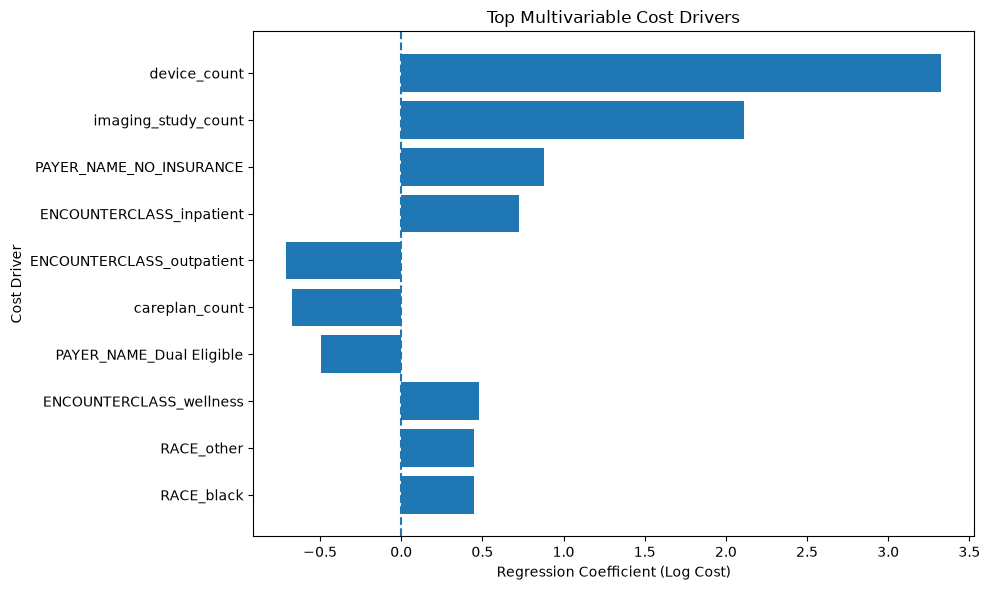

In [85]:
# Q9 - Step 9
# Visualize strongest multivariable cost drivers

import matplotlib.pyplot as plt

top_drivers = coefficient_df.head(10).copy()

# Clean feature names for display
top_drivers["feature_clean"] = (
    top_drivers["feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_drivers["feature_clean"][::-1],
    top_drivers["coefficient"][::-1]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Regression Coefficient (Log Cost)")
plt.ylabel("Cost Driver")
plt.title("Top Multivariable Cost Drivers")

plt.tight_layout()
plt.show()

In [87]:
# Q9 - Step 10
# Identify reference categories used by the regression model

for feature in categorical_features:
    categories = preprocessor.named_transformers_["cat"].categories_[
        categorical_features.index(feature)
    ]

    reference_category = categories[0]

    print(f"{feature}")
    print(f"Reference category: {reference_category}")
    print("-" * 40)

ENCOUNTERCLASS
Reference category: ambulatory
----------------------------------------
PATIENT_GENDER
Reference category: F
----------------------------------------
RACE
Reference category: asian
----------------------------------------
ETHNICITY
Reference category: hispanic
----------------------------------------
PAYER_NAME
Reference category: Aetna
----------------------------------------


In [88]:
# Q10 - Step 1
# Quantify spending associated with high procedure utilization

high_procedure = master[
    master["procedure_count"] >= 6
].copy()

low_procedure = master[
    master["procedure_count"] < 6
].copy()

total_cost = master["TOTAL_CLAIM_COST"].sum()

high_procedure_cost = high_procedure["TOTAL_CLAIM_COST"].sum()
low_procedure_cost = low_procedure["TOTAL_CLAIM_COST"].sum()

high_procedure_share = (
    high_procedure_cost / total_cost
) * 100

print("HIGH PROCEDURE UTILIZATION (>= 6 procedures)")
print("=" * 55)

print("Encounters:", len(high_procedure))
print("Total cost:", round(high_procedure_cost, 2))
print("Average cost:", round(high_procedure["TOTAL_CLAIM_COST"].mean(), 2))
print("Spending share:", round(high_procedure_share, 2), "%")

print("\nLOWER PROCEDURE UTILIZATION (< 6 procedures)")
print("=" * 55)

print("Encounters:", len(low_procedure))
print("Total cost:", round(low_procedure_cost, 2))
print("Average cost:", round(low_procedure["TOTAL_CLAIM_COST"].mean(), 2))

print("\nOVERALL")
print("=" * 55)

print("Total healthcare cost:", round(total_cost, 2))

HIGH PROCEDURE UTILIZATION (>= 6 procedures)
Encounters: 5264
Total cost: 42535900.96
Average cost: 8080.53
Spending share: 16.68 %

LOWER PROCEDURE UTILIZATION (< 6 procedures)
Encounters: 56195
Total cost: 212497927.12
Average cost: 3781.44

OVERALL
Total healthcare cost: 255033828.08


In [89]:
# Q10 - Step 2
# Illustrative savings scenarios for high procedure utilization

scenario_rates = [0.05, 0.10, 0.15]

scenario_results = []

for rate in scenario_rates:
    potential_savings = high_procedure_cost * rate

    scenario_results.append({
        "Scenario": f"{int(rate * 100)}%",
        "Potential_Savings": potential_savings
    })

scenario_df = pd.DataFrame(scenario_results)

print("Illustrative Cost-Optimization Scenarios")
print("=" * 55)

display(scenario_df)

Illustrative Cost-Optimization Scenarios


,Scenario,Potential_Savings
0,5%,2126795.048
1,10%,4253590.096
2,15%,6380385.144


In [91]:
# Q10 - Step 3
# Quantify spending associated with repeat encounters within 30 days

repeat_encounters = master[
    master["REPEAT_30D_FLAG"] == True
].copy()

non_repeat_encounters = master[
    master["REPEAT_30D_FLAG"] == False
].copy()

repeat_cost = repeat_encounters["TOTAL_CLAIM_COST"].sum()
non_repeat_cost = non_repeat_encounters["TOTAL_CLAIM_COST"].sum()

total_cost = master["TOTAL_CLAIM_COST"].sum()

repeat_share = (
    repeat_cost / total_cost
) * 100

print("REPEAT ENCOUNTERS WITHIN 30 DAYS")
print("=" * 55)

print("Encounters:", len(repeat_encounters))
print("Total cost:", round(repeat_cost, 2))
print("Average cost:", round(repeat_encounters["TOTAL_CLAIM_COST"].mean(), 2))
print("Spending share:", round(repeat_share, 2), "%")

print("\nNON-REPEAT ENCOUNTERS")
print("=" * 55)

print("Encounters:", len(non_repeat_encounters))
print("Total cost:", round(non_repeat_cost, 2))
print("Average cost:", round(non_repeat_encounters["TOTAL_CLAIM_COST"].mean(), 2))

REPEAT ENCOUNTERS WITHIN 30 DAYS
Encounters: 22739
Total cost: 143678419.19
Average cost: 6318.59
Spending share: 56.34 %

NON-REPEAT ENCOUNTERS
Encounters: 38720
Total cost: 111355408.89
Average cost: 2875.91


In [92]:
# Q10 - Step 4
# Illustrative savings scenarios for repeat encounters

repeat_scenario_rates = [0.05, 0.10, 0.15]

repeat_scenario_results = []

for rate in repeat_scenario_rates:
    potential_savings = repeat_cost * rate

    repeat_scenario_results.append({
        "Scenario": f"{int(rate * 100)}%",
        "Potential_Savings": potential_savings
    })

repeat_scenario_df = pd.DataFrame(
    repeat_scenario_results
)

print("Illustrative Opportunity - Repeat Encounters")
print("=" * 55)

display(repeat_scenario_df)

Illustrative Opportunity - Repeat Encounters


,Scenario,Potential_Savings
0,5%,7.183921e+06
1,10%,1.436784e+07
2,15%,2.155176e+07


In [93]:
# Q10 - Step 5
# Quantify spending concentration among high-cost patients

high_cost_patient_threshold = patient_summary[
    "total_healthcare_cost"
].quantile(0.99)

high_cost_patients = patient_summary[
    patient_summary["total_healthcare_cost"] >= high_cost_patient_threshold
].copy()

other_patients = patient_summary[
    patient_summary["total_healthcare_cost"] < high_cost_patient_threshold
].copy()

high_cost_patient_spending = (
    high_cost_patients["total_healthcare_cost"].sum()
)

other_patient_spending = (
    other_patients["total_healthcare_cost"].sum()
)

total_patient_spending = (
    patient_summary["total_healthcare_cost"].sum()
)

high_cost_patient_share = (
    high_cost_patient_spending
    / total_patient_spending
) * 100

print("TOP 1% HIGH-COST PATIENTS")
print("=" * 55)

print("Threshold:", round(high_cost_patient_threshold, 2))
print("Patients:", len(high_cost_patients))
print(
    "Total cost:",
    round(high_cost_patient_spending, 2)
)
print(
    "Average patient cost:",
    round(
        high_cost_patients["total_healthcare_cost"].mean(),
        2
    )
)
print(
    "Spending share:",
    round(high_cost_patient_share, 2),
    "%"
)

print("\nOTHER PATIENTS")
print("=" * 55)

print("Patients:", len(other_patients))
print(
    "Total cost:",
    round(other_patient_spending, 2)
)
print(
    "Average patient cost:",
    round(
        other_patients["total_healthcare_cost"].mean(),
        2
    )
)

TOP 1% HIGH-COST PATIENTS
Threshold: 1111270.75
Patients: 12
Total cost: 44674104.28
Average patient cost: 3722842.02
Spending share: 17.52 %

OTHER PATIENTS
Patients: 1151
Total cost: 210359723.8
Average patient cost: 182762.57


In [94]:
# Q10 - Step 6
# Illustrative savings scenarios for high-cost patients

patient_scenario_rates = [0.05, 0.10, 0.15]

patient_scenario_results = []

for rate in patient_scenario_rates:
    potential_savings = (
        high_cost_patient_spending * rate
    )

    patient_scenario_results.append({
        "Scenario": f"{int(rate * 100)}%",
        "Potential_Savings": potential_savings
    })

patient_scenario_df = pd.DataFrame(
    patient_scenario_results
)

print("Illustrative Opportunity - High-Cost Patients")
print("=" * 55)

display(patient_scenario_df)

Illustrative Opportunity - High-Cost Patients


,Scenario,Potential_Savings
0,5%,2233705.214
1,10%,4467410.428
2,15%,6701115.642


In [95]:
# Q10 - Step 7
# Identify overlap between opportunity segments

# Create encounter-level flags
master["HIGH_PROCEDURE_FLAG"] = (
    master["procedure_count"] >= 6
)

master["REPEAT_30D_FLAG"] = (
    master["REPEAT_30D_FLAG"].fillna(False)
)

# Identify top 1% high-cost patients
high_cost_patient_ids = set(
    high_cost_patients["PATIENT"]
)

master["HIGH_COST_PATIENT_FLAG"] = (
    master["PATIENT"].isin(high_cost_patient_ids)
)

# Count encounters in each combination
opportunity_overlap = (
    master.groupby(
        [
            "HIGH_PROCEDURE_FLAG",
            "REPEAT_30D_FLAG",
            "HIGH_COST_PATIENT_FLAG"
        ]
    )
    .agg(
        encounter_count=("Id", "count"),
        total_cost=("TOTAL_CLAIM_COST", "sum")
    )
    .reset_index()
)

print("Opportunity Segment Overlap")
print("=" * 70)

display(opportunity_overlap)

Opportunity Segment Overlap


,HIGH_PROCEDURE_FLAG,REPEAT_30D_FLAG,HIGH_COST_PATIENT_FLAG,encounter_count,total_cost
0,False,False,False,34129,86703493.81
1,False,False,True,1066,10196247.79
2,False,True,False,18176,86909267.88
3,False,True,True,2824,28688917.64
4,True,False,False,3507,14308427.84
5,True,False,True,18,147239.45
6,True,True,False,1524,22438534.27
7,True,True,True,215,5641699.40


In [96]:
# Q10 - Step 8
# Calculate unique spending covered by at least one opportunity pattern

master["ANY_OPPORTUNITY_FLAG"] = (
    master["HIGH_PROCEDURE_FLAG"]
    | master["REPEAT_30D_FLAG"]
    | master["HIGH_COST_PATIENT_FLAG"]
)

opportunity_encounters = master[
    master["ANY_OPPORTUNITY_FLAG"]
].copy()

unique_opportunity_cost = (
    opportunity_encounters["TOTAL_CLAIM_COST"].sum()
)

unique_opportunity_count = len(
    opportunity_encounters
)

total_cost = master["TOTAL_CLAIM_COST"].sum()

unique_opportunity_share = (
    unique_opportunity_cost / total_cost
) * 100

print("UNIQUE OPPORTUNITY POOL")
print("=" * 55)

print(
    "Encounters covered by at least one opportunity:",
    unique_opportunity_count
)

print(
    "Unique opportunity-pool cost:",
    round(unique_opportunity_cost, 2)
)

print(
    "Share of total healthcare spending:",
    round(unique_opportunity_share, 2),
    "%"
)

print("\nTOTAL HEALTHCARE COST")
print("=" * 55)

print(
    "Total cost:",
    round(total_cost, 2)
)

UNIQUE OPPORTUNITY POOL
Encounters covered by at least one opportunity: 27330
Unique opportunity-pool cost: 168330334.27
Share of total healthcare spending: 66.0 %

TOTAL HEALTHCARE COST
Total cost: 255033828.08


In [97]:
# Q10 - Step 9
# Final illustrative opportunity scenarios
# based on the unique opportunity pool

final_scenario_rates = [0.05, 0.10, 0.15]

final_scenario_results = []

for rate in final_scenario_rates:
    potential_savings = (
        unique_opportunity_cost * rate
    )

    final_scenario_results.append({
        "Scenario": f"{int(rate * 100)}%",
        "Potential_Opportunity": potential_savings
    })

final_scenario_df = pd.DataFrame(
    final_scenario_results
)

print("FINAL ILLUSTRATIVE COST-OPTIMIZATION SCENARIOS")
print("=" * 60)

display(final_scenario_df)

FINAL ILLUSTRATIVE COST-OPTIMIZATION SCENARIOS


,Scenario,Potential_Opportunity
0,5%,8.416517e+06
1,10%,1.683303e+07
2,15%,2.524955e+07


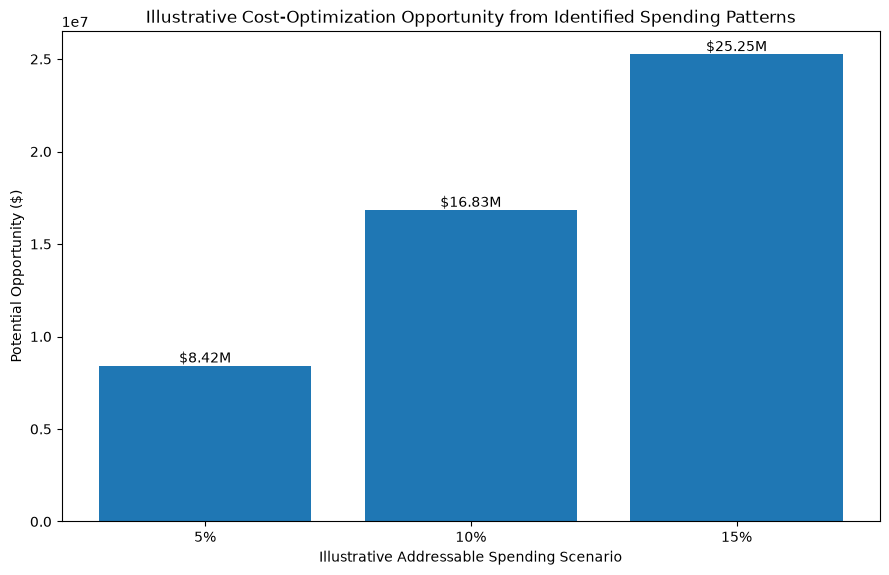

In [98]:
# Q10 - Step 10
# Visualize final illustrative cost-optimization opportunities

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.bar(
    final_scenario_df["Scenario"],
    final_scenario_df["Potential_Opportunity"]
)

plt.xlabel("Illustrative Addressable Spending Scenario")
plt.ylabel("Potential Opportunity ($)")
plt.title(
    "Illustrative Cost-Optimization Opportunity "
    "from Identified Spending Patterns"
)

# Add value labels
for i, value in enumerate(
    final_scenario_df["Potential_Opportunity"]
):
    plt.text(
        i,
        value,
        f"${value / 1_000_000:.2f}M",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()